[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DilaraLiyanage/colombo-rainfall-simulator/blob/main/notebook/colombo-rainfall-simulator.ipynb)

# Colombo Rainfall Simulator

**A reproducible stochastic model of daily rainfall occurrence, intensity and extremes in Colombo, Sri Lanka.**

This notebook reconstructs daily precipitation from 2001–2025, estimates first-order Markov occurrence and lower-truncated Gamma intensity models on 2001–2020, and evaluates synthetic rainfall against the independent 2021–2025 historical period. Analytical expectations and independent Monte Carlo replications verify the implementation before historical validation. A four-season extension and controlled parameter perturbations investigate the research question without refitting the holdout data.

**Main findings from the verified workflow:** conditional intensity dominates marginal P95 exceedance sensitivity over the selected ±20% range; modelling seasonality improves monthly and seasonal rainfall realism, but both models underestimate overall historical P95 risk. The seasonal model is not a universal improvement.

**Reproduction:** use a fresh notebook kernel, run the installation cell and C01–C30 in order, and confirm the final 72-output manifest and 32 scientific figures. The original raw snapshots are validated and all scientific parameters are recalculated within this notebook; previously exported scientific results are not computational inputs. The accompanying [web simulator](https://dilaraliyanage.github.io/colombo-rainfall-simulator/) uses the programmatically exported calibrated model.


## 1. Problem and question

**Research question:** How do rainfall occurrence patterns and intensity influence the probability of extreme rainfall events in Colombo?

Daily rainfall is intermittent, serially dependent and positively skewed. A wet day may be followed by another wet day, and heavy amounts can occur even when the long-run wet frequency is unchanged. Separating the two mechanisms makes their effects on marginal exceedance risk and spell persistence interpretable. Stern and Coe [1] motivate the occurrence–amount decomposition; Wilson Kemsley et al. [3,4] motivate persistence and seasonal diagnostics; the tail comparison is informed by [2,5,6]. Sri Lankan seasonal patterns [7] motivate the predefined four-season extension.

The objectives are to (i) construct and check daily precipitation, (ii) calibrate and compare occurrence and amount models, (iii) verify simulated results against mathematical expectations and convergence, (iv) compare homogeneous and seasonal holdout statistics, and (v) quantify model sensitivity to occurrence and intensity separately and jointly.

Historical associations and mathematical sensitivity are not evidence of environmental causation. The model is exploratory, not a weather or flood forecasting system.


## 2. Model, assumptions and equations

### Daily rainfall and event definitions

Let $h_t$ be the hourly accumulated precipitation (mm) for the hour ending at the exported local time $t$. With the approved accumulation convention, the rainfall total for local date $d$ is

$$R_d=\sum_{t:\operatorname{date}(t-1\,\mathrm{h})=d} h_t.$$

Subtracting an hour before grouping allocates the midnight accumulation to the preceding date. C04 compares this reconstruction to the supplied daily product rather than treating the latter as independent gauge truth.

| Quantity | Definition | Unit / interpretation |
|---|---|---|
| $R_d$ | Original reconstructed daily total | mm over the day |
| $\tau$ | Wet-day threshold, 0.1 | mm |
| $W_d$ | $\mathbf{1}(R_d\geq\tau)$ | 0 dry; 1 wet |
| $R_d^*$ | $R_d W_d$ | Model rainfall, zero on dry days |
| $q_{0.95,\mathrm{cal}}$ | All-day calibration P95 | Primary fixed threshold, mm |
| $q_{0.99,\mathrm{cal}}$ | All-day calibration P99 | Secondary fixed diagnostic, mm |
| $E_d(u)$ | $\mathbf{1}(R_d>u)$ | Strict exceedance indicator |

Both percentiles are recomputed using linear interpolation of **all original daily totals** in 2001–2020, including dry days. They remain fixed for the evaluation period, simulation and all sensitivity scenarios; wet-day distribution quantiles are a different quantity.

### Occurrence–intensity decomposition

The baseline is a homogeneous, first-order, two-state Markov chain with a conditional lower-truncated Gamma wet-day amount. If $S_t$ is the simulated state, its transition probability is $P_{ij}=\Pr(S_t=j\mid S_{t-1}=i)$, where states are ordered dry/wet. On a dry day, $R_t^*=0$; on a wet day, $R_t^*$ follows a positive Gamma parent conditioned on $X\geq\tau$. Conditional amounts are sampled independently given the state and active model parameters. Calibration, theoretical expectations and the seasonal extension are derived in Section 5.


## 3. Implementation

### Historical source and provenance

Open-Meteo Historical Weather API, reported acquisition setting **Best Match**. The supplied acquisition URL was reported to request latitude 6.9355 and longitude 79.8487; both CSV metadata records instead report returned latitude 6.924429, longitude 79.90725 and elevation 4 m. The full query and acquisition date are unavailable, so the relationship between the reported URL and these exact snapshots requires confirmation. Best Match may combine products; the underlying composition is unknown, and no exclusive ERA5/ERA5-Land claim is made. Reanalysis limitations are discussed in [8]. Local timestamps are used as exported (Asia/Colombo, UTC+05:30), without conversion to UTC.

Data attribution: modified Open-Meteo precipitation snapshots, [CC BY 4.0 source credits](https://open-meteo.com/en/license); upstream Copernicus/ECMWF notices apply. See [data provenance and checksums](https://github.com/DilaraLiyanage/colombo-rainfall-simulator/blob/main/data/README.md).

### Execution and data partition

| Period | Inclusive dates | Days | Role |
|---|---|---:|---|
| Calibration | 2001-01-01–2020-12-31 | 7,305 | Estimate thresholds and model parameters |
| Evaluation | 2021-01-01–2025-12-31 | 1,826 | Assess aggregate historical realism only |

The installation cell uses standard Jupyter `%pip` with the exact pins in `requirements.txt`. C01 validates installed **and loaded** scientific versions, selects the repository root or Colab output root, and records configuration. C02 validates both raw byte snapshots before parsing; local execution reads them from `data/raw/`, Colab downloads the same public snapshots. Environment overrides support isolated tests. C30 publishes the final completion manifest only after the required outputs exist. The author reports successful Windows and Colab execution of the frozen scientific implementation. On other runtimes, a preloaded incompatible compiled package can still require a session restart; do not bypass the version check.


**Setup · Install the scientific environment.** Install the four pinned packages in the current Jupyter kernel. The following cell verifies the actual versions; installation alone is not evidence of compatibility.

In [32]:
# Dependency installation (run before C01).
import time
INSTALL_START = time.perf_counter()
%pip install numpy==2.3.5 pandas==2.3.3 scipy==1.17.0 matplotlib==3.10.8


**C01 · Configure paths, dependencies and experiments.** Choose local or Colab acquisition, create output directories and invalidate stale completion evidence. Set the fixed seed, thresholds policy, fit tolerances and replication counts before calculations.

In [33]:
# C01 — Configuration, paths and scientific imports.
import os
import sys
from pathlib import Path

def _repository_root(start: Path):
    """Find the nearest ancestor containing the notebook and raw directory."""
    for candidate in (start, *start.parents):
        if ((candidate / "notebook" / "colombo-rainfall-simulator.ipynb").is_file()
                and (candidate / "data" / "raw").is_dir()):
            return candidate
    return None


_is_colab = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
_root = _repository_root(Path.cwd().resolve())
_local_override = os.environ.get("RAINFALL_DATA_DIR")
_output_override = os.environ.get("RAINFALL_OUTPUT_DIR")
if not _is_colab and _root is None and not _local_override:
    raise FileNotFoundError("Open the notebook inside the repository, or set RAINFALL_DATA_DIR.")
if not _is_colab and _root is None and not _output_override:
    raise ValueError("Set RAINFALL_OUTPUT_DIR when running outside the repository.")
# The repository root (or the runtime directory in Colab) is the default output root.
RESOLVED_OUTPUT = Path(_output_override or (_root if not _is_colab else Path.cwd())).resolve()
RESOLVED_DATA_DIR = Path(_local_override or ((_root or RESOLVED_OUTPUT) / "data" / "raw")).resolve()
USE_LOCAL_DATA = bool(_local_override) or not _is_colab
(RESOLVED_OUTPUT / "data" / "processed").mkdir(parents=True, exist_ok=True)
# Remove stale completion evidence even if dependency setup fails.
(RESOLVED_OUTPUT / "data" / "processed" / "output_manifest.csv").unlink(missing_ok=True)

import sys, importlib.metadata, time, json, platform
RUN_START = INSTALL_START
from pathlib import Path
import os, io, hashlib, urllib.request
PINS = {"numpy": "2.3.5", "pandas": "2.3.3", "scipy": "1.17.0", "matplotlib": "3.10.8"}

# pip changes installed files, not modules already loaded into this kernel.
installed = {name: importlib.metadata.version(name) for name in PINS}
print("Installed scientific versions:", installed)
assert installed == PINS, "Dependency installation failed; inspect the preceding pip output."
preloaded = {
    name: getattr(sys.modules[name], "__version__", None)
    for name in PINS if name in sys.modules
}
print("Previously loaded scientific modules:", preloaded)
assert all(version == PINS[name] for name, version in preloaded.items()), (
    "A scientific package was loaded before installation with a different version. "
    "This runtime cannot safely continue; restart the kernel and run all again."
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib, scipy
assert {
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__
} == PINS, "Loaded scientific versions differ from installed pins"
from IPython.display import display
%matplotlib inline
BOOTSTRAP_SECONDS = time.perf_counter() - INSTALL_START
EXECUTION_MODE = "standard notebook kernel"
print("Python:", platform.python_version())
# Keep scientific settings centralised so later experiments cannot silently choose new seeds or tolerances.
SEED = 42
EXPERIMENT = dict(seed=SEED, verification_reps=600, verification_days=3650,
                  counts=[25, 50, 100, 250, 500, 1000], batches=20, convergence_days=365,
                  holdout_reps=1000, annual_reps=1000, sigma=4, confidence=0.95)
rng = np.random.default_rng(SEED)
# Future independent replications: call once per experiment, then allocate one stream per replicate.

def replication_streams(n):
    return [np.random.default_rng(child) for child in np.random.SeedSequence(SEED).spawn(n)]
QUANTILES = (.95, .99)
FIT_QUANTILES = (.90, .95, .99)
RTOL, ATOL = 1e-8, 1e-9
OPT_SETTINGS = {"ftol": 1e-13, "gtol": 1e-6, "maxiter": 1000}
OPT_BOUNDS = (-10, 12)
DPI = 300
FIGURE_DATA = {}
WET = 0.1
START, END = pd.Timestamp('2001-01-01'), pd.Timestamp('2025-12-31')
CAL_END = pd.Timestamp('2020-12-31')
BASE = 'https://raw.githubusercontent.com/DilaraLiyanage/colombo-rainfall-simulator/main/data/raw/'
# RAINFALL_DATA_DIR optionally points directly to the raw snapshot directory.
DATA_DIR = Path(RESOLVED_DATA_DIR)
OUTPUT = Path(RESOLVED_OUTPUT)
RAW_DIR = OUTPUT / 'data' / 'raw'
PROCESSED_DIR = OUTPUT / 'data' / 'processed'
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT / 'figures').mkdir(parents=True, exist_ok=True)
# A manifest is a completion record, not an input. Invalidate it before work.
(PROCESSED_DIR / 'output_manifest.csv').unlink(missing_ok=True)
print('Scientific versions:', {k: sys.modules[k].__version__ for k in PINS})
print('Output root:', OUTPUT)
print(
    'Runtime:',
    'Colab' if 'COLAB_RELEASE_TAG' in os.environ else 'local Python',
    '| pandas',
    pd.__version__,
    '| numpy',
    np.__version__
)


Installed scientific versions: {'numpy': '2.3.5', 'pandas': '2.3.3', 'scipy': '1.17.0', 'matplotlib': '3.10.8'}
Previously loaded scientific modules: {'numpy': '2.3.5', 'pandas': '2.3.3', 'scipy': '1.17.0', 'matplotlib': '3.10.8'}
Python: 3.13.18
Scientific versions: {'numpy': '2.3.5', 'pandas': '2.3.3', 'scipy': '1.17.0', 'matplotlib': '3.10.8'}
Output root: /content
Runtime: Colab | pandas 2.3.3 | numpy 2.3.5


**C02 · Read immutable precipitation snapshots.** Hash the bytes before parsing; verify metadata equality, local timezone, ordered unique timestamps and valid amounts. The two source snapshots must not be silently repaired.

In [34]:
# C02
# Prefer frozen public snapshot; fall back to existing local file, not interactive upload.
# Explicit local override supports offline, reproducible execution.

def load_export(kind):
    name = f'open-meteo-6.92N79.91E4m-{kind}.csv'
    if USE_LOCAL_DATA:
        path = DATA_DIR / name
        if not path.is_file():
            raise FileNotFoundError(f"Required local snapshot missing: {path}")
        raw = path.read_bytes()
        source = 'local snapshot'
    else:
        with urllib.request.urlopen(BASE + name, timeout=60) as response:
            raw = response.read()
        source = 'GitHub raw'
    # Hash the immutable export bytes before interpreting headers or numeric values.
    expected_sha256 = {'hourly': 'd14a8d9739fdf5337172a82b28226fa446af02919a92dfbef8cc52701d5d9601', 'daily': 'dc672e756178597e04c779eddee2003ae4312003578ea85d0f1730aa5c5fdcda'}
    assert hashlib.sha256(raw).hexdigest() == expected_sha256[kind], f'Snapshot checksum mismatch: {name}'
    meta = pd.read_csv(io.BytesIO(raw), nrows=1)
    frame = pd.read_csv(io.BytesIO(raw), skiprows=3)
    print(kind, source, 'SHA256:', hashlib.sha256(raw).hexdigest(), 'rows:', len(frame))
    display(meta)
    print(frame.columns.tolist())
    return (frame, meta)
hourly, hm = load_export('hourly')
daily_ref, dm = load_export('daily')
assert hm.equals(dm)
assert hm.loc[0, 'timezone'] == 'Asia/Colombo' and hm.loc[0, 'utc_offset_seconds'] == 19800
hourly['time'] = pd.to_datetime(hourly['time'], errors='raise')
daily_ref['time'] = pd.to_datetime(daily_ref['time'], errors='raise')
h = hourly.set_index('time')['precipitation (mm)']
ref = daily_ref.set_index('time')['precipitation_sum (mm)']
assert h.index.is_unique and ref.index.is_unique
assert h.index.is_monotonic_increasing and ref.index.is_monotonic_increasing
assert np.isfinite(h).all() and np.isfinite(ref).all()
assert (h >= 0).all() and (ref >= 0).all()

hourly GitHub raw SHA256: d14a8d9739fdf5337172a82b28226fa446af02919a92dfbef8cc52701d5d9601 rows: 219168


,latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
0,6.924429,79.90725,4.0,19800,Asia/Colombo,GMT+5:30


['time', 'precipitation (mm)']
daily GitHub raw SHA256: dc672e756178597e04c779eddee2003ae4312003578ea85d0f1730aa5c5fdcda rows: 9132


,latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
0,6.924429,79.90725,4.0,19800,Asia/Colombo,GMT+5:30


['time', 'precipitation_sum (mm)', 'precipitation_hours (h)']


**C03 · Reconstruct complete local days.** Select the exact hourly window, group end-of-hour accumulations after shifting timestamps by one hour, and check that every date receives 24 hours. Conservation guards against lost or double-counted precipitation.

In [35]:
# C03
# The first included hour ends at 01:00; the last ends at the following midnight.
expected_hours = pd.date_range(START + pd.Timedelta(hours=1), END + pd.Timedelta(days=1), freq='h')
selected = h.loc[expected_hours[0]:expected_hours[-1]]
assert len(selected) == 219144 and selected.index.equals(expected_hours)
assert selected.notna().all() and (selected >= 0).all()

def aggregate(series, corrected=True):
    # Convert the accumulation-ending timestamp to its containing local day.
    dates = (series.index - pd.Timedelta(hours=int(corrected))).normalize()
    grouped = series.groupby(dates)
    return (grouped.sum(), grouped.size())
rain, counts = aggregate(selected)
assert len(rain) == 9131 and rain.index.equals(pd.date_range(START, END))
assert (counts == 24).all()
# Mass conservation is checked independently of the number of dates.
assert np.isclose(selected.sum(), rain.sum(), rtol=1e-12, atol=1e-08)
print('PASS: hourly continuity, uniqueness, finite nonnegative values, daily coverage, 24/day, mass conservation')
print('Hourly records:', len(selected), 'Daily records:', len(rain), 'Total mm:', rain.sum())

PASS: hourly continuity, uniqueness, finite nonnegative values, daily coverage, 24/day, mass conservation
Hourly records: 219144 Daily records: 9131 Total mm: 68017.7


**C04 · Quantify the aggregation convention.** Compare corrected and uncorrected totals with the provider daily product on the same complete dates. The midnight-difference identity checks the expected change independently; export metrics in C07.

In [36]:
# C04
# Both methods use complete dates, with the extra leading hour available in the original export.
# Difference between methods must equal next midnight minus current midnight.
correct, nc = aggregate(h, True)
uncorrect, nu = aggregate(h, False)
comparison = pd.concat([
    correct.rename('corrected'),
    uncorrect.rename('uncorrected'),
    ref.rename('reference'),
    nc.rename('n_corrected'),
    nu.rename('n_uncorrected')
], axis=1).loc[START:END]
comparison = comparison.loc[(comparison.n_corrected == 24) & (comparison.n_uncorrected == 24)].dropna()
assert len(comparison) == 9131
# Material discrepancy threshold in mm; the extra numerical allowance excludes roundoff.
TOL = 0.1
rows = []
for col in ['corrected', 'uncorrected']:
    err = comparison[col] - comparison.reference
    rows.append({
        'method': col,
        'days': len(err),
        'MAE_mm': err.abs().mean(),
        'RMSE_mm': np.sqrt((err ** 2).mean()),
        'max_abs_mm': err.abs().max(),
        'material_days': int((err.abs() > TOL + 1e-09).sum()),
        'mean_bias_mm': err.mean()
    })
metrics = pd.DataFrame(rows).set_index('method')
display(metrics)
# The corrected total differs only by which midnight boundary is included.
mid = h.reindex(comparison.index).to_numpy()
next_mid = h.reindex(comparison.index + pd.Timedelta(days=1)).to_numpy()
np.testing.assert_allclose(
    comparison.corrected - comparison.uncorrected,
    next_mid - mid,
    atol=1e-09,
    rtol=1e-12
)
print('Largest corrected residuals:')
display(comparison.assign(abs_error=(comparison.corrected - comparison.reference).abs()).nlargest(5, 'abs_error'))
print('Corrected signed residual by year (mm/day):')
display((comparison.corrected - comparison.reference).groupby(comparison.index.year).mean().round(4))

,days,MAE_mm,RMSE_mm,max_abs_mm,material_days,mean_bias_mm
method,,,,,,
corrected,9131,4.060672e-01,1.303786e+00,2.200000e+01,3353,2.101046e-17
uncorrected,9131,1.178677e-16,5.944685e-16,1.421085e-14,0,2.898666e-17


Largest corrected residuals:


,corrected,uncorrected,reference,n_corrected,n_uncorrected,abs_error
time,,,,,,
2006-11-06,56.6,34.6,34.6,24,24.0,22.0
2006-11-07,89.7,111.7,111.7,24,24.0,22.0
2006-11-16,44.8,63.0,63.0,24,24.0,18.2
2006-11-15,32.9,14.7,14.7,24,24.0,18.2
2021-03-27,53.1,35.0,35.0,24,24.0,18.1


Corrected signed residual by year (mm/day):


,0
time,
2001,0.0000
2002,-0.0000
2003,0.0000
2004,0.0000
2005,0.0000
2006,-0.0000
2007,0.0000
2008,-0.0000
2009,0.0000


**C05 · Build historical features and freeze thresholds.** Keep original daily rainfall separate from model rainfall, derive wet/dry flags and seasons, split chronologically, and calculate the all-day calibration P95 and P99. Export the three daily datasets.

In [37]:
# C05
# The exports have centesimal precision; round only binary summation noise, not physical values.
df = rain.rename('rainfall_mm').rename_axis('date').reset_index()
df['rainfall_mm'] = df.rainfall_mm.round(10)
df['is_wet'] = df.rainfall_mm >= WET
df['model_rainfall_mm'] = df.rainfall_mm.where(df.is_wet, 0.0)
df['year'] = df.date.dt.year
df['month'] = df.date.dt.month
season_map = {
    1: 'NEM',
    2: 'NEM',
    3: 'FIM',
    4: 'FIM',
    5: 'SWM',
    6: 'SWM',
    7: 'SWM',
    8: 'SWM',
    9: 'SWM',
    10: 'SIM',
    11: 'SIM',
    12: 'NEM'
}
df['season'] = df.month.map(season_map)
df['split'] = np.where(df.date <= CAL_END, 'calibration', 'evaluation')
# Only calibration dates define the extreme thresholds; evaluation data cannot leak into estimation.
cal_mask = df.split.eq('calibration')
q95, q99 = df.loc[cal_mask, 'rainfall_mm'].quantile(list(QUANTILES), interpolation='linear').to_numpy()
df['is_extreme'] = df.rainfall_mm > q95
columns = [
    'date',
    'rainfall_mm',
    'model_rainfall_mm',
    'is_wet',
    'year',
    'month',
    'season',
    'is_extreme',
    'split'
]
df = df[columns]
cal = df.loc[cal_mask].copy()
evaluation = df.loc[~cal_mask].copy()
print(f'Calibration q95={q95:.6f} mm; q99={q99:.6f} mm')
for label, part in [('all', df), ('calibration', cal), ('evaluation', evaluation)]:
    loss = (part.rainfall_mm - part.model_rainfall_mm).sum()
    print(label, 'trace loss mm:', round(loss, 6), 'percent:', 100 * loss / part.rainfall_mm.sum())
for name, part in [
    ('processed_daily', df),
    ('calibration_daily', cal),
    ('evaluation_daily', evaluation)
]:
    part.to_csv(PROCESSED_DIR / f'{name}.csv', index=False, date_format='%Y-%m-%d')

Calibration q95=25.200000 mm; q99=46.296000 mm
all trace loss mm: 0.0 percent: 0.0
calibration trace loss mm: 0.0 percent: 0.0
evaluation trace loss mm: 0.0 percent: 0.0


## 4. Verification

**Preprocessing verification** checks the data contract before modelling: complete hourly coverage; finite, nonnegative amounts; 24 accumulation hours per day; conservation of total precipitation; no duplicate or missing dates; and contiguous, disjoint calibration and evaluation ranges. Missing hours are not imputed as zero. A deterministic midnight/leap-day example checks the timestamp convention independently of the full dataset.

**Model verification** later checks deterministic cases, distribution support and analytical agreement (C09–C19, C24–C25). Historical holdout **validation** (C21 and C26–C27) assesses whether the model represents observed aggregate properties; it is not a test of exact daily predictions. These are different scientific questions.


**C06 · Test calendar, classification and split invariants.** The deterministic leap-day example tests accumulation boundaries. Assertions verify chronological separation, six leap days, fixed threshold calculation and zero model rainfall on dry days.

In [38]:
# C06
toy = pd.Series([2.0, 3.0, 5.0], index=pd.to_datetime([
    '2020-02-29 23:00',
    '2020-03-01 00:00',
    '2020-03-01 01:00'
]))
toy_daily, _ = aggregate(toy)
assert toy_daily.loc['2020-02-29'] == 5 and toy_daily.loc['2020-03-01'] == 5
assert len(cal) == 7305 and len(evaluation) == 1826
assert cal.date.is_monotonic_increasing and evaluation.date.is_monotonic_increasing
assert not set(cal.date) & set(evaluation.date)
assert cal.date.iloc[0] == START and cal.date.iloc[-1] == CAL_END
assert evaluation.date.iloc[0] == pd.Timestamp('2021-01-01') and evaluation.date.iloc[-1] == END
assert len(df[df.date.dt.strftime('%m-%d') == '02-29']) == 6
assert (df.is_extreme == (df.rainfall_mm > q95)).all()
assert (df.is_wet == (df.rainfall_mm >= WET)).all()
assert (df.loc[~df.is_wet, 'model_rainfall_mm'] == 0).all()
assert q95 == cal.rainfall_mm.quantile(0.95)
print('PASS: midnight/leap example, six leap days, chronological disjoint splits, fixed calibration threshold and wet classification')
display(toy_daily)

PASS: midnight/leap example, six leap days, chronological disjoint splits, fixed calibration threshold and wet classification


,0
2020-02-29,5.0
2020-03-01,5.0


## 5. Experiments and results

### Historical exploratory analysis

The reconstructed series contains 219,144 selected hourly records and 9,131 daily totals. Previous-run thresholds are 25.2 mm (P95) and 46.296 mm (P99), recalculated from calibration data in C05. The historical calibration wet-day frequency is 86.01%, compared with 92.22% in the evaluation period. Descriptive evaluation summaries are reported transparently, not used to select fitted parameters or thresholds.

Monthly climatology is the mean of calendar-month **totals** over the years, not the mean daily precipitation in each month. F01–F07 show historical rainfall, climatology, wet-day distribution, seasonal differences and the aggregation comparison before any synthetic rainfall is introduced.


**C07 · Summarise calibration and evaluation data.** Compute descriptive rainfall, wet frequency, intensity and extreme frequency separately for both periods. Export summary and aggregation metrics without using holdout statistics to tune the model.

In [39]:
# C07

def describe(part):
    x = part.rainfall_mm
    return pd.Series({
        'days': len(part),
        'total_mm': x.sum(),
        'mean_mm_day': x.mean(),
        'std_mm_day': x.std(),
        'median_mm': x.median(),
        'max_mm': x.max(),
        'wet_days': part.is_wet.sum(),
        'wet_frequency': part.is_wet.mean(),
        'mean_wet_mm': part.loc[part.is_wet, 'rainfall_mm'].mean(),
        'extreme_days': part.is_extreme.sum(),
        'extreme_frequency': part.is_extreme.mean()
    })
summary = pd.DataFrame({'calibration': describe(cal), 'evaluation (historical)': describe(evaluation)})
display(summary)
print('Calibration seasonal summaries:')
display(cal.groupby('season').apply(describe, include_groups=False))
summary.to_csv(PROCESSED_DIR / 'summary.csv')
metrics.to_csv(PROCESSED_DIR / 'aggregation_metrics.csv')

,calibration,evaluation (historical)
days,7305.000000,1826.000000
total_mm,52521.100000,15496.600000
mean_mm_day,7.189747,8.486637
std_mm_day,10.384421,11.759587
median_mm,3.600000,4.200000
max_mm,240.200000,204.600000
wet_days,6283.000000,1684.000000
wet_frequency,0.860096,0.922234
mean_wet_mm,8.359239,9.202257
extreme_days,365.000000,149.000000


Calibration seasonal summaries:


,days,total_mm,mean_mm_day,std_mm_day,median_mm,max_mm,wet_days,wet_frequency,mean_wet_mm,extreme_days,extreme_frequency
season,,,,,,,,,,,
FIM,1220.0,6333.6,5.191475,8.121758,2.3,81.4,1100.0,0.901639,5.757818,38.0,0.031148
NEM,1805.0,6080.9,3.368920,7.604891,0.3,97.4,1028.0,0.569529,5.915272,44.0,0.024377
SIM,1220.0,14456.9,11.849918,14.422237,7.7,133.0,1135.0,0.930328,12.737357,150.0,0.122951
SWM,3060.0,25649.7,8.382255,9.690734,5.6,240.2,3020.0,0.986928,8.493278,133.0,0.043464


**C08 · Generate historical diagnostics F01–F07.** Plot the actual reconstructed data and provider comparisons. The shared figure helper saves 300 DPI PNGs, captures numerical primitives for regression and closes figures after display.

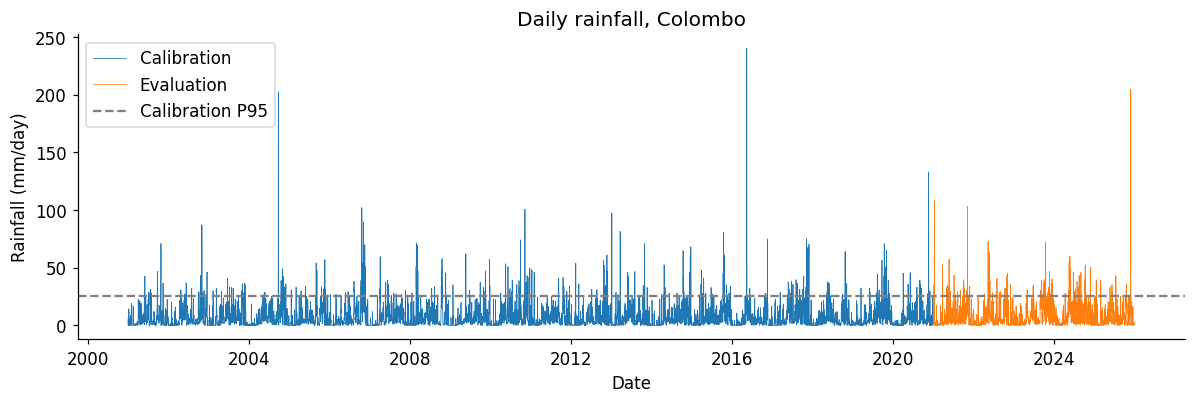

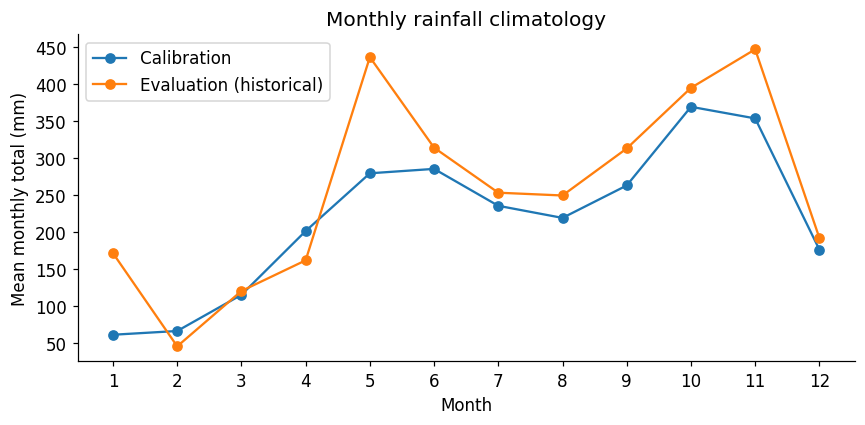

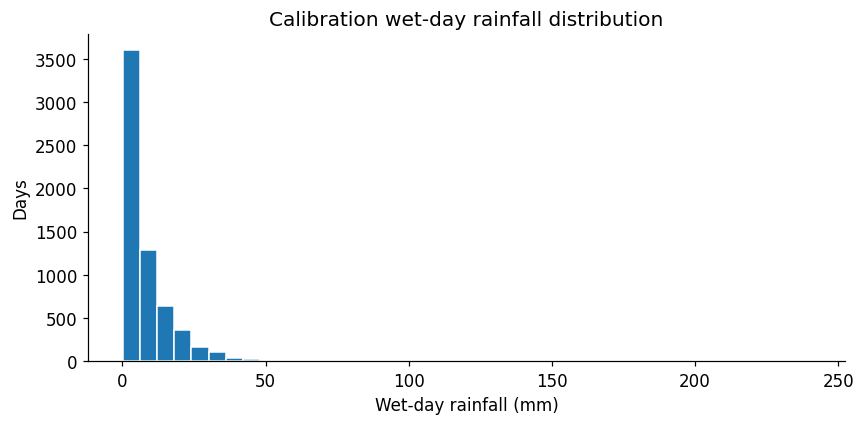

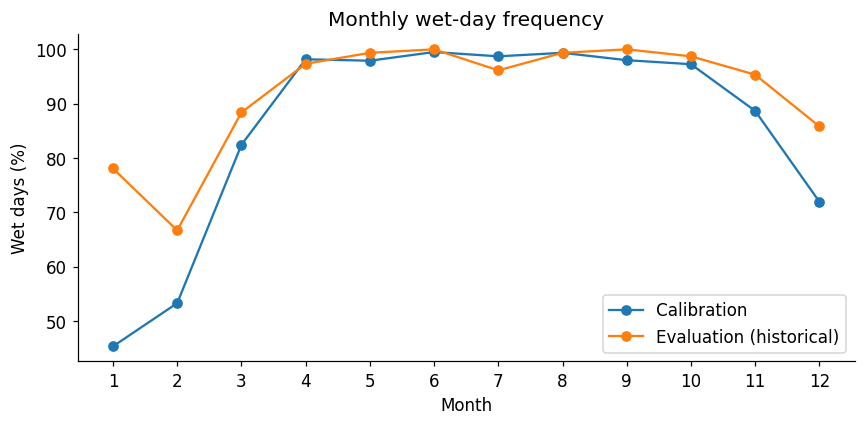

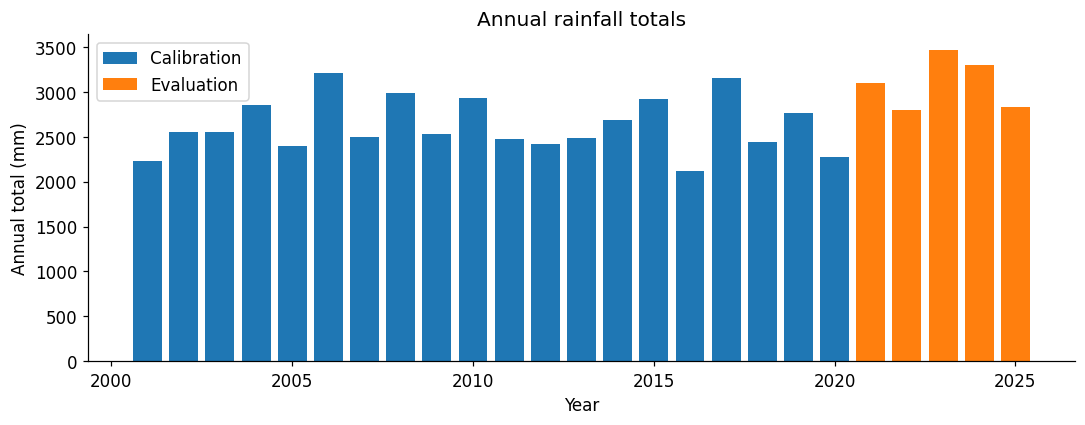

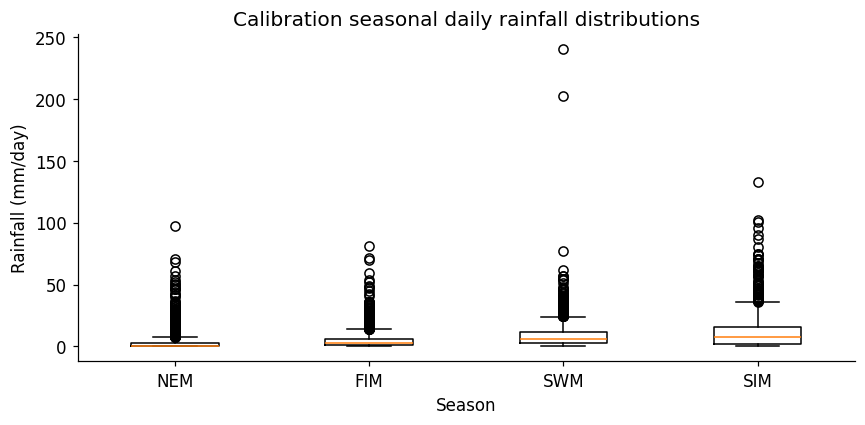

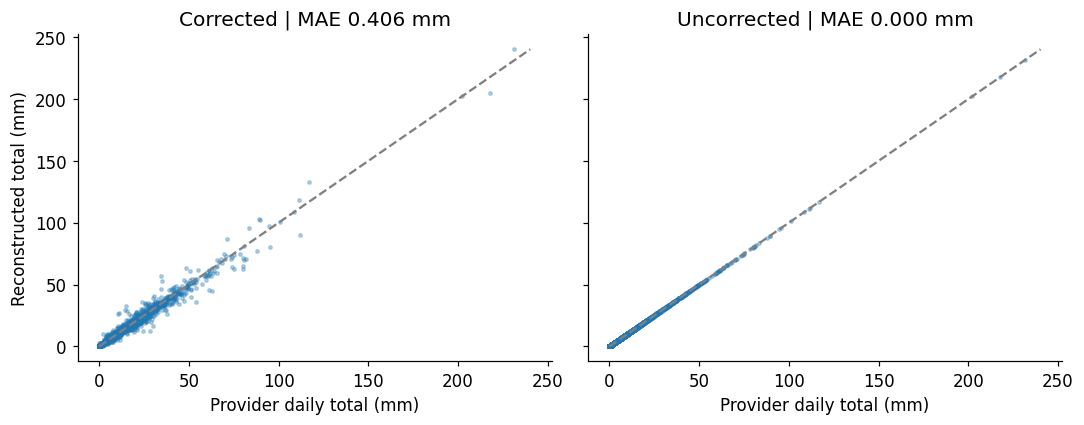

In [40]:
# C08
# Capture plotted numerical primitives, independent of raster rendering.
plt.style.use('default')
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 110
})

def finish(fig, name):
    # Capture numerical plot primitives before rendering; compare these across platforms.
    payload = []
    for ax in fig.axes:

        def arr(v):
            return np.asarray(v).tolist()
        payload.append({
            'lines': [[arr(l.get_xdata(orig=False)), arr(l.get_ydata(orig=False))] for l in ax.lines],
            'images': [arr(im.get_array()) for im in ax.images],
            'collections': [arr(col.get_offsets()) for col in ax.collections],
            'rectangles': [[
                patch.get_x(),
                patch.get_y(),
                patch.get_width(),
                patch.get_height()
            ] for patch in ax.patches if hasattr(patch, 'get_width')],
            'paths': [arr(patch.get_path().vertices) for patch in ax.patches if not hasattr(patch, 'get_width')]
        })
    if int(name[1:3]) >= 15:
        for ax, entry in zip(fig.axes, payload):
            entry['collection_segments'] = [[arr(seg) for seg in collection.get_segments()] for collection in ax.collections if hasattr(collection, 'get_segments')]
            entry['collection_paths'] = [[arr(path.vertices) for path in collection.get_paths()] for collection in ax.collections]
    FIGURE_DATA[name] = payload
    fig.tight_layout()
    fig.savefig(OUTPUT / 'figures' / f'{name}.png', dpi=DPI, bbox_inches='tight')
    plt.show()
    plt.close(fig)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(cal.date, cal.rainfall_mm, lw=0.5, label='Calibration')
ax.plot(evaluation.date, evaluation.rainfall_mm, lw=0.5, label='Evaluation')
ax.axhline(q95, ls='--', color='gray', label='Calibration P95')
ax.set(ylabel='Rainfall (mm/day)', xlabel='Date', title='Daily rainfall, Colombo')
ax.legend()
finish(fig, 'F01_daily_rainfall')
fig, ax = plt.subplots(figsize=(8, 4))
for part, label in [(cal, 'Calibration'), (evaluation, 'Evaluation (historical)')]:
    monthly = part.groupby(['year', 'month']).rainfall_mm.sum().groupby('month').mean()
    ax.plot(monthly.index, monthly.values, marker='o', label=label)
ax.set(
    xticks=range(1, 13),
    xlabel='Month',
    ylabel='Mean monthly total (mm)',
    title='Monthly rainfall climatology'
)
ax.legend()
finish(fig, 'F02_monthly_climatology')
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(cal.loc[cal.is_wet, 'rainfall_mm'], bins=40, edgecolor='white')
ax.set(xlabel='Wet-day rainfall (mm)', ylabel='Days', title='Calibration wet-day rainfall distribution')
finish(fig, 'F03_wet_day_histogram')
fig, ax = plt.subplots(figsize=(8, 4))
for part, label in [(cal, 'Calibration'), (evaluation, 'Evaluation (historical)')]:
    s = part.groupby('month').is_wet.mean() * 100
    ax.plot(s.index, s.values, marker='o', label=label)
ax.set(xticks=range(1, 13), xlabel='Month', ylabel='Wet days (%)', title='Monthly wet-day frequency')
ax.legend()
finish(fig, 'F04_monthly_wet_frequency')
fig, ax = plt.subplots(figsize=(10, 4))
for part, label in [(cal, 'Calibration'), (evaluation, 'Evaluation')]:
    s = part.groupby('year').rainfall_mm.sum()
    ax.bar(s.index, s.values, label=label)
ax.set(xlabel='Year', ylabel='Annual total (mm)', title='Annual rainfall totals')
ax.legend()
finish(fig, 'F05_annual_rainfall')
fig, ax = plt.subplots(figsize=(8, 4))
seasons = ['NEM', 'FIM', 'SWM', 'SIM']
ax.boxplot([cal.loc[cal.season == s, 'rainfall_mm'] for s in seasons])
ax.set(
    xticks=range(1, 5),
    xticklabels=seasons,
    ylabel='Rainfall (mm/day)',
    xlabel='Season',
    title='Calibration seasonal daily rainfall distributions'
)
finish(fig, 'F06_seasonal_distributions')
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
limit = comparison[['reference', 'corrected', 'uncorrected']].max().max()
for ax, col in zip(axs, ['corrected', 'uncorrected']):
    ax.scatter(comparison.reference, comparison[col], s=5, alpha=0.3)
    ax.plot([0, limit], [0, limit], ls='--', color='gray')
    ax.set(xlabel='Provider daily total (mm)', title=col.capitalize() + f" | MAE {metrics.loc[col, 'MAE_mm']:.3f} mm")
axs[0].set_ylabel('Reconstructed total (mm)')
finish(fig, 'F07_daily_aggregation_comparison')

### Calibration of rainfall occurrence

Only the contiguous calibration record `cal` is used for estimation. For each chronological pair $(S_{t-1},S_t)$, count $n_{ij}$ for dry/wet states $i,j\in\{0,1\}$. The maximum-likelihood estimate is

$$\hat p_{ij}=\frac{n_{ij}}{\sum_{k=0}^{1}n_{ik}},\qquad P=\begin{bmatrix}p_{00}&p_{01}\\p_{10}&p_{11}\end{bmatrix}.$$

The rows sum to one. The stationary distribution of the fitted homogeneous chain satisfies $\boldsymbol\pi P=\boldsymbol\pi$, $\pi_0+\pi_1=1$, hence

$$\pi_1=\frac{p_{01}}{p_{01}+p_{10}},\qquad \pi_0=\frac{p_{10}}{p_{01}+p_{10}}.$$

A complete spell of state $i$ has a geometric length under this homogeneous model:

$$\Pr(L_i=l)=p_{i,1-i}p_{ii}^{l-1},\qquad E[L_i]=\frac{1}{p_{i,1-i}},\quad l=1,2,\ldots.$$

Exclude both endpoint runs from the empirical complete-spell analysis because their full lengths outside the observed interval are unknown. Compare first-order dependence with independent (order-zero) occurrence using identical 7,304 destination observations and conditional likelihoods. The Bayesian information criterion $\mathrm{BIC}=-2\ell+k\log n$ uses one free parameter for order zero and two for order one; lower BIC is preferred, but it does not establish realistic higher-order persistence [3].


**C09 · Estimate Markov transitions and order comparison.** Count 7,304 adjacent calibration pairs, normalise by origin state and verify stationarity. Evaluate conditional BIC on the same destination observations and export transition and BIC tables.

In [41]:
# C09
from scipy import stats, optimize, integrate
from scipy.special import xlogy
assert len(cal) == 7305 and cal.date.min() == pd.Timestamp('2001-01-01') and (cal.date.max() == CAL_END)
assert cal.date.diff().iloc[1:].eq(pd.Timedelta(days=1)).all()
assert np.isclose(q95, 25.2, rtol=RTOL, atol=ATOL) and np.isclose(q99, 46.296, rtol=RTOL, atol=ATOL)
s = cal.is_wet.to_numpy(dtype=int)
# Build adjacent chronological pairs before selecting seasons to avoid artificial transitions.
pairs = pd.DataFrame({'previous': s[:-1], 'current': s[1:], 'season': cal.season.to_numpy()[1:]})

def transition_counts(pair):
    counts = np.zeros((2, 2), dtype=int)
    np.add.at(counts, (pair.previous.to_numpy(), pair.current.to_numpy()), 1)
    assert counts.sum() == len(pair) and (counts.sum(axis=1) > 0).all()
    matrix = counts / counts.sum(axis=1, keepdims=True)
    assert np.all((matrix >= 0) & (matrix <= 1)) and np.allclose(matrix.sum(axis=1), 1)
    return (counts, matrix)
N, P = transition_counts(pairs)
assert N.sum() == 7304
pi = np.array([P[1, 0], P[0, 1]]) / (P[0, 1] + P[1, 0])
assert np.all(pi >= 0) and np.isclose(pi.sum(), 1) and np.allclose(pi @ P, pi)
# Compare conditional likelihoods over exactly the same destination observations.
ll1 = xlogy(N, P).sum()
dest = N.sum(axis=0)
ll0 = xlogy(dest, dest / dest.sum()).sum()
occurrence_bic = pd.DataFrame({'order': [0, 1], 'log_likelihood': [ll0, ll1], 'parameters': [1, 2]})
occurrence_bic['BIC'] = -2 * occurrence_bic.log_likelihood + occurrence_bic.parameters * np.log(len(pairs))
transition_table = pd.DataFrame([{
    'from_state': i,
    'to_state': j,
    'count': N[i, j],
    'probability': P[i, j]
} for i in range(2) for j in range(2)])
transition_table.to_csv(PROCESSED_DIR / 'markov_transitions.csv', index=False)
occurrence_bic.to_csv(PROCESSED_DIR / 'occurrence_bic.csv', index=False)
display(transition_table, occurrence_bic)
print('Stationary dry/wet:', pi, 'Empirical wet frequency:', s.mean())
print('Transition and stationary assertions passed.')

,from_state,to_state,count,probability
0,0,0,670,0.655577
1,0,1,352,0.344423
2,1,0,352,0.056033
3,1,1,5930,0.943967


,order,log_likelihood,parameters,BIC
0,0,-2956.836554,1,5922.569286
1,1,-2014.438536,2,4046.669426


Stationary dry/wet: [0.13992333 0.86007667] Empirical wet frequency: 0.8600958247775496
Transition and stationary assertions passed.


**C10 · Compare complete spell durations.** Identify runs using state changes and discard endpoint-censored runs. Export empirical spell summaries alongside geometric expectations to reveal limitations beyond mean length.

In [42]:
# C10
# First and last runs may be censored; retain only complete interior spells.
boundaries = np.r_[0, np.flatnonzero(np.diff(s)) + 1, len(s)]
lengths = np.diff(boundaries)
states = s[boundaries[:-1]]
assert lengths.sum() == len(s)
spells = {i: lengths[1:-1][states[1:-1] == i] for i in (0, 1)}
spell_summary = pd.DataFrame([{
    'state': i,
    'complete_spells': len(v),
    'empirical_mean_days': v.mean(),
    'median_days': np.median(v),
    'max_days': v.max(),
    'p95_days': np.quantile(v, 0.95),
    'theoretical_mean_days': 1 / P[i, 1 - i]
} for i, v in spells.items()])
spell_summary.to_csv(PROCESSED_DIR / 'spell_statistics.csv', index=False)
display(spell_summary)
print('Excluded endpoint runs:', lengths[[0, -1]])

,state,complete_spells,empirical_mean_days,median_days,max_days,p95_days,theoretical_mean_days
0,0,352,2.903409,2.0,18,10.0,2.903409
1,1,351,17.871795,4.0,245,106.5,17.846591


Excluded endpoint runs: [4 6]


### Lower-truncated intensity likelihood

Let $f_\theta$ and $F_\theta$ be the parent density and CDF; $\bar F_\theta(x)=1-F_\theta(x)$ is its survival function. For a wet-day amount $x\geq\tau=0.1$ mm,

$$g_\theta(x)=\frac{f_\theta(x)}{\bar F_\theta(\tau)},\qquad x\geq\tau,$$

and $g_\theta(x)=0$ below the wet threshold. For $n$ calibration wet amounts, the conditional log-likelihood is

$$\ell(\theta)=\sum_{i=1}^n\log f_\theta(x_i)-n\log\bar F_\theta(\tau).$$

The normalisation term is essential; fitting an ordinary Gamma and clipping samples would change the distribution. Gamma shape $\alpha$ is dimensionless and scale $\beta$ is measured in mm. The exponential fit has one scale parameter; Gamma and log-normal each have two. The parent location is fixed at zero. Positive parameters are optimised on log scales with multiple deterministic starts, and survival functions avoid subtracting nearly equal probabilities in the tail.

For probability $u\in[0,1)$ the conditional quantile is $\bar F_\theta^{-1}((1-u)\bar F_\theta(\tau))$, where the inverse denotes the inverse survival function. Conditional Gamma mean is $\alpha\beta\bar F_{\alpha+1,\beta}(\tau)/\bar F_{\alpha,\beta}(\tau)$; the exponential mean is $\tau+\beta$; the log-normal conditional mean is $e^{\mu+\sigma^2/2}\Phi((\mu+\sigma^2-\log\tau)/\sigma)/\bar F(\tau)$, with $\mu$ the parent log-location and $\sigma$ the log-scale standard deviation.

Evaluate $\mathrm{AIC}=2k-2\ell$ and $\mathrm{BIC}=k\log n-2\ell$, conditional quantiles and fixed-threshold tails. The information criteria describe relative fit, not absolute adequacy. Serial dependence and rounded rainfall measurements limit interpretation of the independent continuous likelihood; no unadjusted fitted-distribution goodness-of-fit p-value is decisive.


**C11 · Fit truncated conditional intensity.** Use wet calibration amounts only. Optimise normalised Gamma, exponential and log-normal likelihoods in log-parameter space, check convergence and density integration, and export the fit diagnostics.

In [43]:
# C11
x = cal.loc[cal.is_wet, 'rainfall_mm'].to_numpy()
assert len(x) == s.sum() and np.all(x >= WET)

def parent(name, z):
    a = np.exp(z)
    if name == 'Gamma':
        return stats.gamma(a[0], loc=0, scale=a[1])
    if name == 'Exponential':
        return stats.expon(loc=0, scale=a[0])
    if name == 'Log-normal':
        return stats.lognorm(a[0], loc=0, scale=a[1])
    raise ValueError(name)

def fit_truncated(name, values):
    assert np.all(values >= WET)
    if name == 'Gamma':
        init = np.log(stats.gamma.fit(values, floc=0)[::2])
    elif name == 'Exponential':
        init = np.log([values.mean() - WET])
    else:
        init = np.log(stats.lognorm.fit(values, floc=0)[::2])

    # Subtract log survival at the wet threshold for every observation in the truncated likelihood.
    def objective(z):
        d = parent(name, z)
        v = -(d.logpdf(values).sum() - len(values) * d.logsf(WET))
        return v if np.isfinite(v) else 1e+100
    # Deterministic restarts reduce sensitivity to the initial optimisation point.
    starts = [init, init + 0.4, init - 0.4]
    results = [optimize.minimize(
        objective,
        z,
        method='L-BFGS-B',
        bounds=[OPT_BOUNDS] * len(z),
        options=OPT_SETTINGS
    ) for z in starts]
    good = [r for r in results if r.success and np.isfinite(r.fun)]
    assert good, name
    best = min(good, key=lambda r: r.fun)
    assert best.fun <= objective(init) + 1e-06 and np.all(np.abs(best.x) < 9.99)
    d = parent(name, best.x)
    # Check that the conditional density, not the parent density over all support, integrates to one.
    norm = d.sf(WET)
    assert norm > 0 and np.isclose(
        integrate.quad(lambda t: d.pdf(t) / norm, WET, np.inf)[0],
        1,
        atol=1e-07
    )
    return (d, best, results)
names = ['Gamma', 'Exponential', 'Log-normal']
fits = {name: fit_truncated(name, x) for name in names}

def survival(d, t):
    return np.where(np.asarray(t) < WET, 1.0, d.sf(t) / d.sf(WET))

def quantile(d, u):
    return d.isf((1 - np.asarray(u)) * d.sf(WET))

def fit_row(name, fit, values):
    d, r, rs = fit
    pars = np.exp(r.x)
    k = len(pars)
    ll = -r.fun
    return {
        'distribution': name,
        'n': len(values),
        'shape': pars[0] if k == 2 else np.nan,
        'scale_mm': pars[-1],
        'log_likelihood': ll,
        'AIC': 2 * k - 2 * ll,
        'BIC': k * np.log(len(values)) - 2 * ll,
        'converged': r.success,
        'successful_starts': sum((t.success for t in rs)),
        'iterations': r.nit,
        'gradient_inf_norm': np.max(np.abs(r.jac)),
        'normalisation': d.sf(WET)
    }
fit_table = pd.DataFrame([fit_row(name, fit, x) for name, fit in fits.items()])
fit_table.to_csv(PROCESSED_DIR / 'distribution_fits.csv', index=False)
display(fit_table)
print('All selected optimisations converged; truncated densities integrate to one.')

,distribution,n,shape,scale_mm,log_likelihood,AIC,BIC,converged,successful_starts,iterations,gradient_inf_norm,normalisation
0,Gamma,6283,0.708847,11.343818,-19389.890899,38783.781799,38797.273004,True,3,9,0.000364,0.961744
1,Exponential,6283,NaN,8.259239,-19548.501964,39099.003929,39105.749531,True,3,5,0.000000,0.987965
2,Log-normal,6283,1.352630,4.129066,-19702.582815,39409.165630,39422.656836,True,3,9,0.000728,0.997026


All selected optimisations converged; truncated densities integrate to one.


**C12 · Inspect conditional quantiles and fixed-threshold tails.** Compare empirical wet-day P90/P95/P99 with fitted quantiles and evaluate signed conditional exceedance errors at the fixed all-day thresholds. Export both diagnostic tables.

In [44]:
# C12
# Compare conditional wet-day quantiles and strict exceedance at fixed all-day thresholds.
qs = FIT_QUANTILES
thresholds = [q95, q99]
quantile_table = pd.DataFrame([{
    'distribution': name,
    'quantile': u,
    'observed_mm': np.quantile(x, u),
    'fitted_mm': quantile(fit[0], u),
    'error_mm': quantile(fit[0], u) - np.quantile(x, u)
} for name, fit in fits.items() for u in qs])
tail_table = pd.DataFrame([{
    'distribution': name,
    'threshold_mm': t,
    'observed_wet_exceedance': np.mean(x > t),
    'fitted_wet_exceedance': float(survival(fit[0], t)),
    'error': float(survival(fit[0], t)) - np.mean(x > t)
} for name, fit in fits.items() for t in thresholds])
quantile_table.to_csv(PROCESSED_DIR / 'distribution_quantiles.csv', index=False)
tail_table.to_csv(PROCESSED_DIR / 'distribution_tail_errors.csv', index=False)
display(quantile_table, tail_table)

,distribution,quantile,observed_mm,fitted_mm,error_mm
0,Gamma,0.90,20.000,20.521050,0.521050
1,Gamma,0.95,26.800,27.651071,0.851071
2,Gamma,0.99,48.754,44.643744,-4.110256
3,Exponential,0.90,20.000,19.117601,-0.882399
4,Exponential,0.95,26.800,24.842470,-1.957530
5,Exponential,0.99,48.754,38.135202,-10.618798
6,Log-normal,0.90,20.000,23.425171,3.425171
7,Log-normal,0.95,26.800,38.278271,11.478271
8,Log-normal,0.99,48.754,96.182844,47.428844


,distribution,threshold_mm,observed_wet_exceedance,fitted_wet_exceedance,error
0,Gamma,25.200,0.058093,0.063347,0.005253
1,Gamma,46.296,0.011778,0.008569,-0.003209
2,Exponential,25.200,0.058093,0.047882,-0.010212
3,Exponential,46.296,0.011778,0.003723,-0.008055
4,Log-normal,25.200,0.058093,0.090842,0.032749
5,Log-normal,46.296,0.011778,0.037088,0.025310


### Analytical benchmarks and seasonal preparation

Let $Q(a,z)$ denote the regularised upper incomplete Gamma function. The lower-truncated Gamma conditional mean is

$$m_X=\alpha\beta\frac{Q(\alpha+1,\tau/\beta)}{Q(\alpha,\tau/\beta)}.$$

For the stationary homogeneous occurrence model and conditionally independent amounts,

$$E[R]=\pi_1 m_X,\qquad \Pr(R>u)=\pi_1\frac{\bar F_\theta(u)}{\bar F_\theta(\tau)},\quad u\geq\tau.$$

These deterministic expectations are independent verification targets, not realised frequencies from synthetic trajectories. Numerical quadrature checks the Gamma mean and exceedance calculations.

For season-specific calibration, first construct adjacent chronological pairs, then classify each pair by its **destination date**. This includes cross-season transitions but never joins nonconsecutive dates. The seasons follow [7]:

| Season | Months |
|---|---|
| NEM (northeast monsoon) | December–February |
| FIM (first intermonsoon) | March–April |
| SWM (southwest monsoon) | May–September |
| SIM (second intermonsoon) | October–November |

Each season has its own transition matrix and lower-truncated Gamma fit. The calendar-dependent chain does not have a single homogeneous stationary distribution.


**C13 · Calculate independent stationary analytical targets.** Compute the conditional mean, daily rainfall and exceedance probabilities, and spell expectations. Use numerical quadrature as a separate normalisation/expectation check; export analytical benchmarks.

In [45]:
# C13
from scipy.special import gammaincc
G = fits['Gamma'][0]
alpha = G.args[0]
beta = G.kwds['scale']
wet_mean = alpha * beta * gammaincc(alpha + 1, WET / beta) / gammaincc(alpha, WET / beta)
# Numerical integration is independent of the incomplete-Gamma moment identity.
quad_mean = integrate.quad(lambda t: t * G.pdf(t) / G.sf(WET), WET, np.inf)[0]
assert np.isclose(wet_mean, quad_mean, rtol=1e-08)
for t in thresholds:
    assert np.isclose(
        survival(G, t),
        integrate.quad(lambda v: G.pdf(v) / G.sf(WET), t, np.inf)[0],
        rtol=1e-08
    )
bench = pd.DataFrame([
    ('stationary_wet_probability', pi[1], s.mean()),
    ('mean_wet_mm', wet_mean, x.mean()),
    ('expected_daily_mm', pi[1] * wet_mean, cal.model_rainfall_mm.mean()),
    ('mean_wet_spell_days', 1 / P[1, 0], spells[1].mean()),
    ('mean_dry_spell_days', 1 / P[0, 1], spells[0].mean()),
    ('daily_P95_exceedance', pi[1] * survival(G, q95), np.mean(cal.rainfall_mm > q95)),
    ('daily_P99_exceedance', pi[1] * survival(G, q99), np.mean(cal.rainfall_mm > q99))
], columns=['metric', 'analytical', 'historical_calibration'])
bench.to_csv(PROCESSED_DIR / 'analytical_benchmarks.csv', index=False)
display(bench)
print('Analytical mean and exceedances independently checked by quadrature.')

,metric,analytical,historical_calibration
0,stationary_wet_probability,0.860077,0.860096
1,mean_wet_mm,8.359239,8.359239
2,expected_daily_mm,7.189586,7.189747
3,mean_wet_spell_days,17.846591,17.871795
4,mean_dry_spell_days,2.903409,2.903409
5,daily_P95_exceedance,0.054483,0.049966
6,daily_P99_exceedance,0.007370,0.010130


Analytical mean and exceedances independently checked by quadrature.


**C14 · Fit the four calendar-specific parameter blocks.** Partition already-adjacent transition pairs by destination season. Fit the same truncated Gamma likelihood in each season and verify that seasonal counts exactly reconstruct the homogeneous counts.

In [46]:
# C14
seasons = ['NEM', 'FIM', 'SWM', 'SIM']
seasonal_rows = []
seasonal_counts = []
for season in seasons:
    # Pairs were created chronologically; season filtering cannot create new adjacent pairs.
    counts, matrix = transition_counts(pairs[pairs.season == season])
    values = cal.loc[cal.is_wet & cal.season.eq(season), 'rainfall_mm'].to_numpy()
    fit = fit_truncated('Gamma', values)
    row = fit_row('Gamma', fit, values)
    row['season'] = season
    for i in (0, 1):
        for j in (0, 1):
            row[f'n{i}{j}'] = counts[i, j]
            row[f'p{i}{j}'] = matrix[i, j]
    seasonal_rows.append(row)
    seasonal_counts.append(counts)
assert np.array_equal(np.sum(seasonal_counts, axis=0), N)
seasonal = pd.DataFrame(seasonal_rows)
seasonal.to_csv(PROCESSED_DIR / 'seasonal_parameters.csv', index=False)
display(seasonal)
print('Seasonal counts exactly partition the homogeneous counts; all fits converged.')

,distribution,n,shape,scale_mm,log_likelihood,AIC,BIC,converged,successful_starts,iterations,...,normalisation,season,n00,p00,n01,p01,n10,p10,n11,p11
0,Gamma,1028,0.258186,16.126726,-2612.187012,5228.374024,5238.244764,True,3,10,...,0.702860,NEM,566,0.727506,212,0.272494,211,0.205653,815,0.794347
1,Gamma,1100,0.470697,10.715368,-2905.691818,5815.383637,5825.389768,True,3,10,...,0.875282,FIM,54,0.428571,72,0.571429,66,0.060329,1028,0.939671
2,Gamma,3020,1.166920,7.233504,-9428.199965,18860.399930,18872.425954,True,3,9,...,0.993796,SWM,10,0.256410,29,0.743590,30,0.009930,2991,0.990070
3,Gamma,1135,0.795474,15.705930,-3999.702066,8003.404133,8013.472909,True,3,9,...,0.980800,SIM,40,0.506329,39,0.493671,45,0.039439,1096,0.960561


Seasonal counts exactly partition the homogeneous counts; all fits converged.


**C15 · Generate calibration diagnostics F08–F14.** Display transition probabilities, spell survival, density/CDF/Q–Q fits, tail discrepancies and seasonal transitions. These plots assess fitted-model properties before simulation.

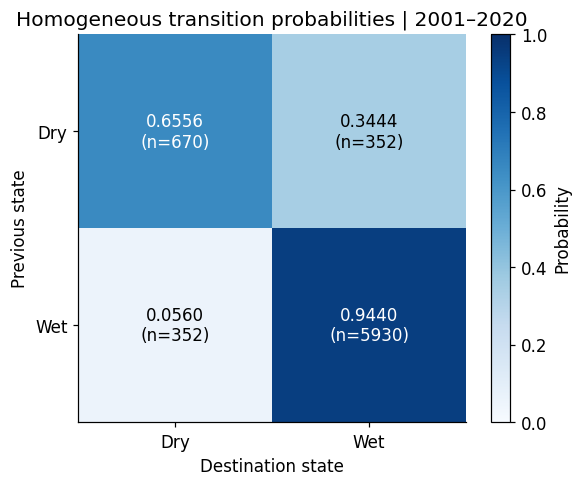

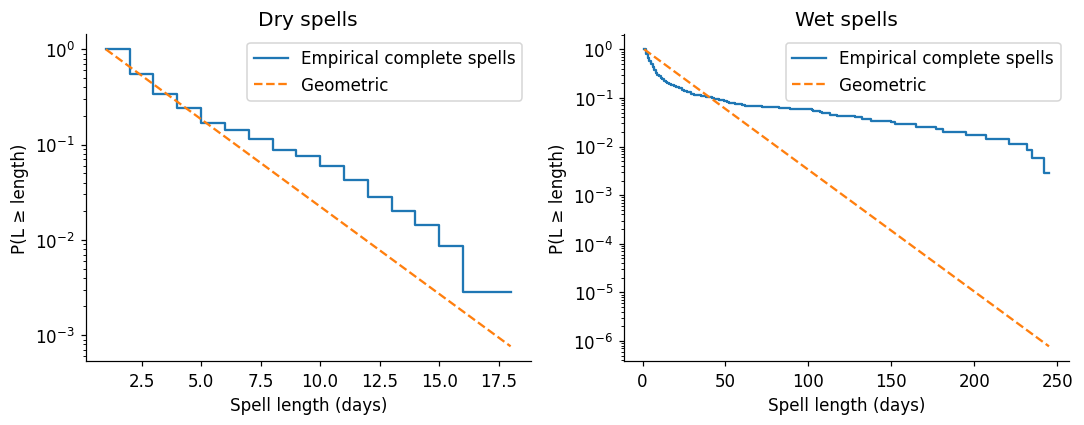

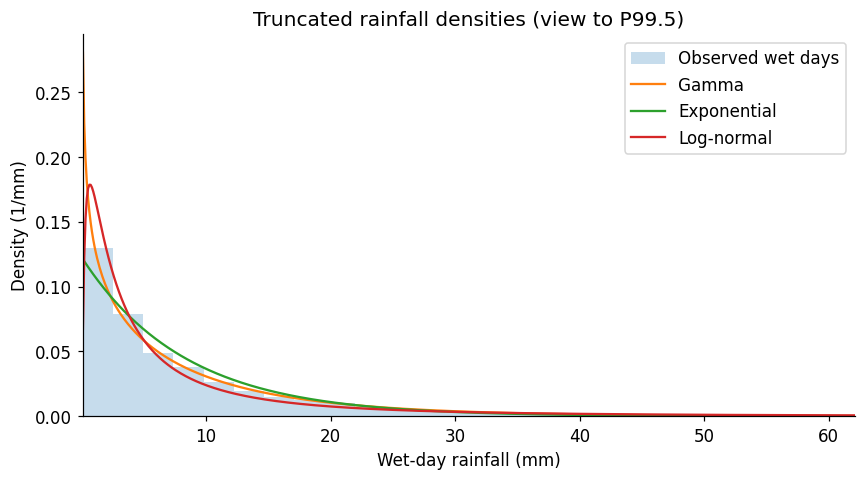

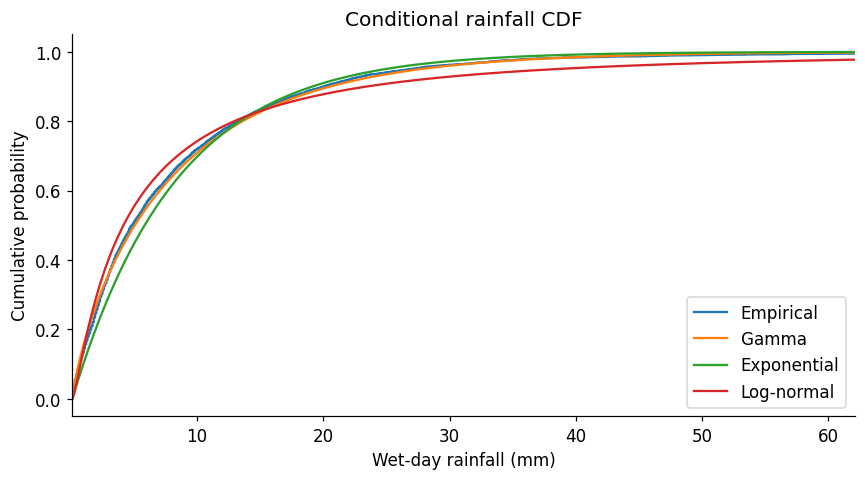

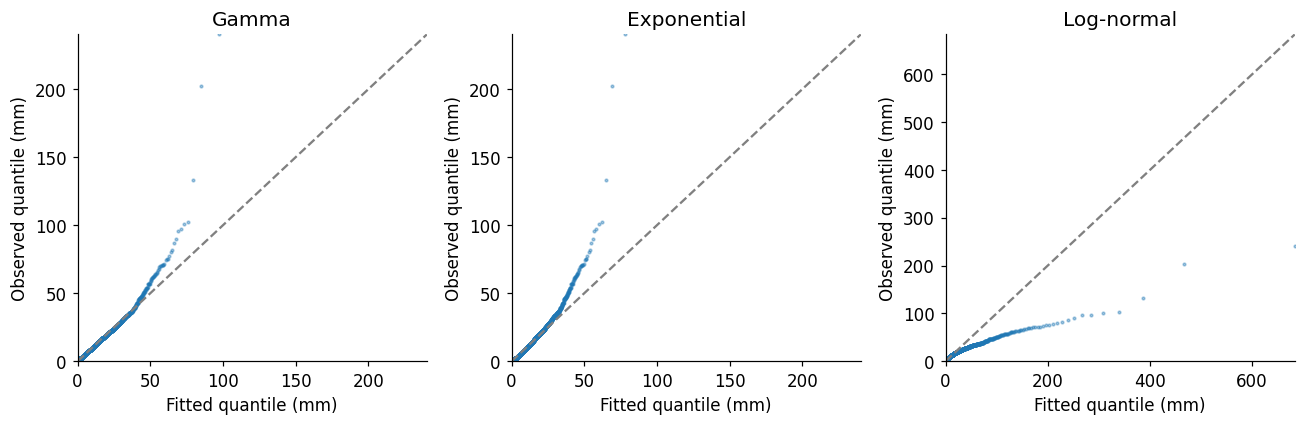

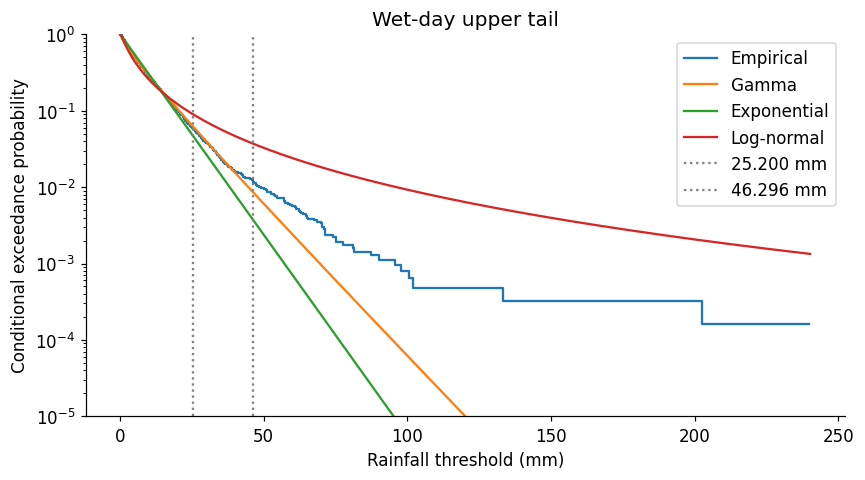

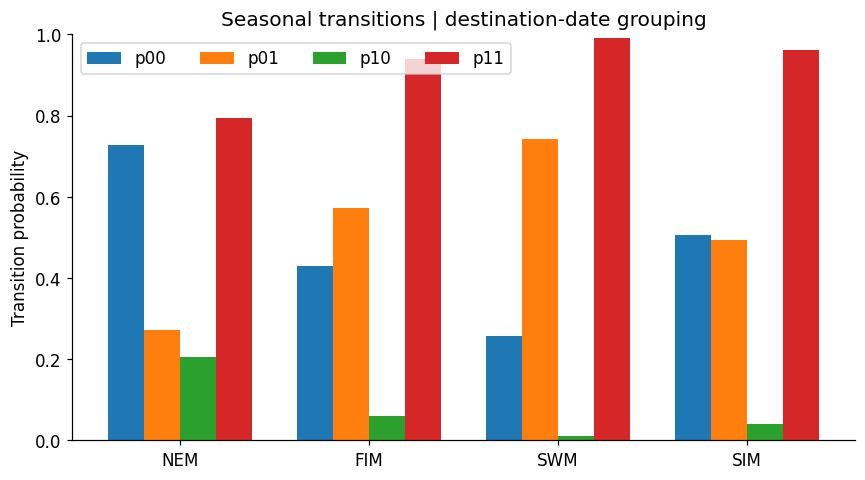

In [47]:
# C15
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(P, vmin=0, vmax=1, cmap='Blues')
for i in (0, 1):
    for j in (0, 1):
        ax.text(j, i, f'{P[i, j]:.4f}\n(n={N[i, j]})', ha='center', va='center', color='white' if P[i, j] > 0.5 else 'black')
ax.set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=['Dry', 'Wet'],
    yticklabels=['Dry', 'Wet'],
    xlabel='Destination state',
    ylabel='Previous state',
    title='Homogeneous transition probabilities | 2001–2020'
)
fig.colorbar(im, ax=ax, label='Probability')
finish(fig, 'F08_transition_matrix')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for i, ax in enumerate(axes):
    v = spells[i]
    k = np.arange(1, max(v) + 1)
    ax.step(k, [np.mean(v >= t) for t in k], where='post', label='Empirical complete spells')
    ax.plot(k, stats.geom.sf(k - 1, P[i, 1 - i]), label='Geometric', ls='--')
    ax.set(
        yscale='log',
        xlabel='Spell length (days)',
        ylabel='P(L ≥ length)',
        title=['Dry spells', 'Wet spells'][i]
    )
    ax.legend()
finish(fig, 'F09_spell_distributions')
grid = np.linspace(WET, np.quantile(x, 0.995), 600)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(x, bins=np.linspace(WET, x.max(), 100), density=True, alpha=0.25, label='Observed wet days')
for name, (d, *_) in fits.items():
    ax.plot(grid, d.pdf(grid) / d.sf(WET), label=name)
ax.set(
    xlim=(WET, grid[-1]),
    xlabel='Wet-day rainfall (mm)',
    ylabel='Density (1/mm)',
    title='Truncated rainfall densities (view to P99.5)'
)
ax.legend()
finish(fig, 'F10_fitted_densities')
fig, ax = plt.subplots(figsize=(8, 4.5))
sx = np.sort(x)
ax.step(sx, np.arange(1, len(x) + 1) / len(x), where='post', label='Empirical')
for name, (d, *_) in fits.items():
    ax.plot(grid, 1 - survival(d, grid), label=name)
ax.set(
    xlim=(WET, grid[-1]),
    xlabel='Wet-day rainfall (mm)',
    ylabel='Cumulative probability',
    title='Conditional rainfall CDF'
)
ax.legend()
finish(fig, 'F11_fitted_cdfs')
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
u = (np.arange(1, len(x) + 1) - 0.5) / len(x)
for ax, (name, (d, *_)) in zip(axes, fits.items()):
    theoretical = quantile(d, u)
    lim = max(sx.max(), theoretical.max())
    ax.scatter(theoretical, sx, s=3, alpha=0.4)
    ax.plot([0, lim], [0, lim], ls='--', color='gray')
    ax.set(
        xlabel='Fitted quantile (mm)',
        ylabel='Observed quantile (mm)',
        title=name,
        xlim=(0, lim),
        ylim=(0, lim)
    )
finish(fig, 'F12_distribution_qq')
fig, ax = plt.subplots(figsize=(8, 4.5))
tgrid = np.linspace(WET, x.max(), 500)
empirical = np.array([np.mean(x > t) for t in tgrid])
ax.step(tgrid[empirical > 0], empirical[empirical > 0], where='post', label='Empirical')
for name, (d, *_) in fits.items():
    ax.plot(tgrid, survival(d, tgrid), label=name)
for t in thresholds:
    ax.axvline(t, ls=':', color='gray', label=f'{t:.3f} mm')
ax.set(
    yscale='log',
    ylim=(1e-05, 1),
    xlabel='Rainfall threshold (mm)',
    ylabel='Conditional exceedance probability',
    title='Wet-day upper tail'
)
ax.legend()
finish(fig, 'F13_upper_tail')
fig, ax = plt.subplots(figsize=(8, 4.5))
pos = np.arange(4)
width = 0.19
for k, key in enumerate(['p00', 'p01', 'p10', 'p11']):
    ax.bar(pos + (k - 1.5) * width, seasonal[key], width, label=key)
ax.set(
    xticks=pos,
    xticklabels=seasons,
    ylim=(0, 1),
    ylabel='Transition probability',
    title='Seasonal transitions | destination-date grouping'
)
ax.legend(ncol=4)
finish(fig, 'F14_seasonal_transitions')

### Calibration findings

The verified calibration counts are $N=\begin{bmatrix}670&352\\352&5930\end{bmatrix}$. Wet-to-wet probability is approximately 94.40%; dry-to-wet probability is 34.44%. The first-order conditional BIC (4046.67) is lower than order zero (5922.57) by 1875.90, showing dependence relative to independence, not sufficiency of one-day memory. The geometric model has mean wet-spell length 17.85 days, close to the empirical 17.87 days, but the complete empirical spells have median 4 days and maximum 245 days. The SWM dry-origin row has only 39 transitions, so that estimate warrants particular caution.

Gamma achieves the lowest AIC and BIC among the three candidates. Its conditional wet-day P99 is underestimated (44.64 versus 48.754 mm), whereas the log-normal overestimates it (96.18 mm). Gamma's stationary daily exceedance probabilities are 5.4483% and 0.7370% at the fixed all-day P95 and P99, respectively, versus historical calibration frequencies 4.9966% and 1.0130%. These are fitted-model discrepancies, not simulation errors. The retained Gamma baseline is justified by overall fit but has imperfect tail accuracy [2,5,6].

These values are rounded verified results for interpretation; each execution recomputes the full-precision estimates. No parameter is obtained from this Markdown narrative.


### Reproducibility inventory

C16 exports the calibrated parameter and analytical tables, records loaded scientific versions and registers F01–F14. Later cells extend the inventory. **C30 alone writes the final completion manifest**, after verifying the 32-figure numerical inventory and expected file presence. Every scientific result originates from the validated raw snapshots and current-run parameters. PNGs can vary across rendering platforms; numerical plotting primitives are saved separately in `figure_data.json`.

The optional read-only `verify_reproducibility.py` compares completed output roots against a frozen reference with metric-aware rules. Historical values, event counts and scientific configurations remain exact; continuous fitted parameters have narrow numerical tolerances, and optimisation diagnostics are checked for quality. The notebook does not depend on the comparison utility to produce results.


**C16 · Register calibration outputs and runtime versions.** Export the current-run parameters and numerical figure data, verify dependency versions and register the calibration output inventory. The final completion record is deferred to C30.

In [48]:
# C16
# Output inventory is declarative; all listed scientific outputs are generated above.
manifest = pd.DataFrame([
    {'path': 'data/processed/processed_daily.csv', 'cell': 'C05', 'description': 'processed daily'},
    {'path': 'data/processed/calibration_daily.csv', 'cell': 'C05', 'description': 'calibration daily'},
    {'path': 'data/processed/evaluation_daily.csv', 'cell': 'C05', 'description': 'evaluation daily'},
    {'path': 'data/processed/summary.csv', 'cell': 'C07', 'description': 'summary'},
    {
        'path': 'data/processed/aggregation_metrics.csv',
        'cell': 'C07',
        'description': 'aggregation metrics'
    },
    {
        'path': 'data/processed/markov_transitions.csv',
        'cell': 'C09',
        'description': 'markov transitions'
    },
    {'path': 'data/processed/occurrence_bic.csv', 'cell': 'C09', 'description': 'occurrence bic'},
    {'path': 'data/processed/spell_statistics.csv', 'cell': 'C10', 'description': 'spell statistics'},
    {'path': 'data/processed/distribution_fits.csv', 'cell': 'C11', 'description': 'distribution fits'},
    {
        'path': 'data/processed/distribution_quantiles.csv',
        'cell': 'C12',
        'description': 'distribution quantiles'
    },
    {
        'path': 'data/processed/distribution_tail_errors.csv',
        'cell': 'C12',
        'description': 'distribution tail errors'
    },
    {
        'path': 'data/processed/analytical_benchmarks.csv',
        'cell': 'C13',
        'description': 'analytical benchmarks'
    },
    {
        'path': 'data/processed/seasonal_parameters.csv',
        'cell': 'C14',
        'description': 'seasonal parameters'
    },
    {'path': 'data/processed/output_manifest.csv', 'cell': 'C16', 'description': 'output manifest'},
    {'path': 'data/processed/runtime_versions.csv', 'cell': 'C16', 'description': 'runtime versions'},
    {'path': 'figures/F01_daily_rainfall.png', 'cell': 'C08', 'description': 'daily rainfall'},
    {'path': 'figures/F02_monthly_climatology.png', 'cell': 'C08', 'description': 'monthly climatology'},
    {'path': 'figures/F03_wet_day_histogram.png', 'cell': 'C08', 'description': 'wet day histogram'},
    {
        'path': 'figures/F04_monthly_wet_frequency.png',
        'cell': 'C08',
        'description': 'monthly wet frequency'
    },
    {'path': 'figures/F05_annual_rainfall.png', 'cell': 'C08', 'description': 'annual rainfall'},
    {
        'path': 'figures/F06_seasonal_distributions.png',
        'cell': 'C08',
        'description': 'seasonal distributions'
    },
    {
        'path': 'figures/F07_daily_aggregation_comparison.png',
        'cell': 'C08',
        'description': 'daily aggregation comparison'
    },
    {'path': 'figures/F08_transition_matrix.png', 'cell': 'C15', 'description': 'transition matrix'},
    {'path': 'figures/F09_spell_distributions.png', 'cell': 'C15', 'description': 'spell distributions'},
    {'path': 'figures/F10_fitted_densities.png', 'cell': 'C15', 'description': 'fitted densities'},
    {'path': 'figures/F11_fitted_cdfs.png', 'cell': 'C15', 'description': 'fitted cdfs'},
    {'path': 'figures/F12_distribution_qq.png', 'cell': 'C15', 'description': 'distribution qq'},
    {'path': 'figures/F13_upper_tail.png', 'cell': 'C15', 'description': 'upper tail'},
    {
        'path': 'figures/F14_seasonal_transitions.png',
        'cell': 'C15',
        'description': 'seasonal transitions'
    },
    {
        'path': 'data/processed/figure_data.json',
        'cell': 'C16',
        'description': 'Numerical plotting primitives for regression comparison'
    }
])
manifest.loc[len(manifest)] = [
    'data/processed/model_parameters.json',
    'C16',
    'Calibrated homogeneous and seasonal model parameters for future consumers'
]
model_export = {
    'schema_version': 1,
    'calibration_start': START.date().isoformat(),
    'calibration_end': CAL_END.date().isoformat(),
    'seed': SEED,
    'wet_threshold_mm': WET,
    'extreme_threshold_mm': float(q95),
    'secondary_threshold_mm': float(q99),
    'state_order': ['dry', 'wet'],
    'homogeneous': {'transition_matrix': P.tolist(), 'stationary_distribution': pi.tolist(), 'amount_distribution': {
        'name': 'lower_truncated_gamma',
        'shape': float(alpha),
        'scale_mm': float(beta),
        'lower_mm': WET,
        'parent_location_mm': 0
    }},
    'seasonal': {row['season']: {'transition_matrix': [[float(row['p00']), float(row['p01'])], [float(row['p10']), float(row['p11'])]], 'amount_distribution': {
        'name': 'lower_truncated_gamma',
        'shape': float(row['shape']),
        'scale_mm': float(row['scale_mm']),
        'lower_mm': WET,
        'parent_location_mm': 0
    }} for row in seasonal_rows}
}
(PROCESSED_DIR / 'model_parameters.json').write_text(json.dumps(model_export, indent=2, allow_nan=False) + '\n', encoding='utf-8')
(PROCESSED_DIR / 'figure_data.json').write_text(json.dumps(FIGURE_DATA, default=str, sort_keys=True), encoding='utf-8')
actual_versions = {k: sys.modules[k].__version__ for k in PINS}
assert {k: importlib.metadata.version(k) for k in PINS} == PINS
assert actual_versions == PINS
runtime = pd.DataFrame([
    {'component': 'python', 'version': platform.python_version()},
    *[{'component': k, 'version': v} for k, v in actual_versions.items()],
    *[{'component': k, 'version': importlib.metadata.version(k)} for k in ('ipython', 'matplotlib-inline')]
])
runtime.to_csv(PROCESSED_DIR / 'runtime_versions.csv', index=False)
assert all(((OUTPUT / path).is_file() for path in manifest.path if path != "data/processed/output_manifest.csv"))
assert len(FIGURE_DATA) == 14
print(
    'Generated outputs:',
    len(manifest),
    '| elapsed seconds:',
    round(time.perf_counter() - RUN_START, 2)
)
display(runtime)

Generated outputs: 31 | elapsed seconds: 41.72


,component,version
0,python,3.13.18
1,numpy,2.3.5
2,pandas,2.3.3
3,scipy,1.17.0
4,matplotlib,3.10.8
5,ipython,7.34.0
6,matplotlib-inline,0.2.2


### Homogeneous generator

For preceding state $i$, draw $U_t\sim\mathcal U(0,1)$ and set

$$S_t=\mathbf{1}(U_t<p_{i1}).$$

On a wet day, an independent uniform $V_t$ is transformed by the conditional inverse survival function:

$$X_t=\beta Q^{-1}\left(\alpha,(1-V_t)Q(\alpha,\tau/\beta)\right).$$

Dry days receive exactly zero rainfall. The $V_t=0$ endpoint maps mathematically to $\tau$; no untruncated Gamma sample is clipped. Each trajectory consumes a deterministic sequence of origin, occurrence and intensity uniforms; separate experiment namespaces and child `SeedSequence` streams preserve independence between replications and repeatability within a configuration.

Initial state means the state of the **day before** the first simulated date. Stationary verification samples this origin from the unique stationary law, while historical evaluation uses the last observed calibration state. Two absorbing classes require explicit initialisation; an alternating chain can have a unique stationary law without convergence from an arbitrary origin.


**C17 · Define the reusable homogeneous generator.** Validate domain and stationary-law assumptions; generate chronological binary states and exact conditional amounts from independent uniforms. Compute per-trajectory statistics and uncertainty without treating individual days as independent.

In [49]:
# C17
from scipy.special import gammainccinv

def validate(matrix, shape, scale, lower):
    """Check the model domain before sampling."""
    assert matrix.shape == (2, 2), 'Matrix must be 2 by 2'
    assert np.isfinite(matrix).all() and ((matrix >= 0) & (matrix <= 1)).all(), 'Invalid probability'
    np.testing.assert_allclose(matrix.sum(axis=1), 1, rtol=0, atol=ATOL)
    assert np.isfinite([shape, scale, lower]).all() and min(shape, scale, lower) > 0, 'Invalid Gamma parameters'

def stationary(matrix):
    """Unique stationary distribution; reject two absorbing classes."""
    denominator = matrix[0, 1] + matrix[1, 0]
    if denominator == 0:
        raise ValueError('No unique stationary distribution')
    return np.array([matrix[1, 0], matrix[0, 1]]) / denominator

def generate_states(matrix, uniforms, origins):
    """Generate chronologically dependent states across independent trajectories."""
    states = np.empty(uniforms.shape, dtype=np.int8)
    previous = origins.copy()
    for day in range(uniforms.shape[1]):
        previous = (uniforms[:, day] < matrix[previous, 1]).astype(np.int8)
        states[:, day] = previous
    return states

def sample_amounts(uniforms, shape, scale, lower):
    """Exact conditional inverse survival sampling, without clipping."""
    uniforms = np.asarray(uniforms)
    assert np.isfinite(uniforms).all() and ((uniforms >= 0) & (uniforms < 1)).all(), "Uniforms must lie in [0, 1)"
    values = scale * gammainccinv(shape, (1 - uniforms) * gammaincc(shape, lower / scale))
    # Exact zero uniform maps to the lower endpoint, avoiding inverse-roundoff.
    return np.where(uniforms == 0, lower, values)

def ensemble(
    days: int,
    reps: int,
    matrix: np.ndarray,
    shape: float,
    scale: float,
    lower: float,
    seed: int=SEED,
    namespace: tuple=(),
    initial=None
):
    """Initial state denotes the day before the first simulated day."""
    validate(matrix, shape, scale, lower)
    assert days > 0 and reps > 0 and initial in (None, 0, 1)
    # Namespace the seed tree by experiment; one child supplies each independent trajectory.
    children = np.random.SeedSequence(seed, spawn_key=namespace).spawn(reps)
    assert len({c.spawn_key for c in children}) == reps
    u = np.empty((reps, days))
    v = np.empty_like(u)
    origins = np.empty(reps, dtype=np.int8)
    prob = stationary(matrix)[1] if initial is None else initial
    for i, child in enumerate(children):
        generator = np.random.default_rng(child)
        # Always consume the origin draw, even for an explicit origin, preserving stream alignment.
        origins[i] = generator.random() < prob
        u[i] = generator.random(days)
        v[i] = generator.random(days)
    states = generate_states(matrix, u, origins)
    amounts = np.zeros(states.shape)
    # Only wet-state amounts are transformed; dry values remain exactly zero.
    wet = states == 1
    amounts[wet] = sample_amounts(v[wet], shape, scale, lower)
    return states, amounts

def trajectory(days, matrix, shape, scale, lower, seed=SEED, initial=None):
    """Generate a single rainfall trajectory."""
    states, amounts = ensemble(days, 1, matrix, shape, scale, lower, seed, initial=initial)
    return states[0], amounts[0]

def complete_spells(states, state):
    """Exclude potentially censored first and last spells."""
    boundaries = np.r_[0, np.flatnonzero(np.diff(states)) + 1, len(states)]
    return np.diff(boundaries)[1:-1][states[boundaries[:-1]][1:-1] == state]

def trajectory_stats(states, amounts, primary, secondary):
    """Compute one observation per independent trajectory."""
    count = states.sum(axis=1)
    result = pd.DataFrame(dict(
        stationary_wet_probability=states.mean(axis=1),
        expected_daily_mm=amounts.mean(axis=1),
        mean_wet_mm=np.divide(
            amounts.sum(axis=1),
            count,
            out=np.full(len(states), np.nan),
            where=count > 0
        ),
        daily_P95_exceedance=(amounts > primary).mean(axis=1),
        daily_P99_exceedance=(amounts > secondary).mean(axis=1)
    ))
    for state, label in [(0, 'dry'), (1, 'wet')]:
        runs = [complete_spells(row, state) for row in states]
        result[f'mean_{label}_spell_days']=[v.mean() if len(v) else np.nan for v in runs]
    return result

def uncertainty(values):
    """Student-t confidence interval and empirical trajectory prediction interval."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    n = len(values)
    assert n >= 2
    mean = values.mean()
    se = values.std(ddof=1) / np.sqrt(n)
    half = stats.t.ppf((1 + EXPERIMENT["confidence"]) / 2, n - 1) * se
    lo, hi = np.quantile(values, [.025, .975])
    return dict(n=n, mean=mean, mcse=se, ci_low=mean - half, ci_high=mean + half, pi_low=lo, pi_high=hi)
MODEL = (P, alpha, beta, WET)

**C18 · Run deterministic and seeded verification tests.** Exercise absorbing and alternating chains, independent Bernoulli occurrence, valid support, reproducibility, inverse survival identity, spell accounting and strict exceedance. Export the 21 check outcomes.

In [50]:
# C18
checks = []

def check(name, condition):
    assert condition, name
    checks.append(dict(test=name, outcome='PASS'))
for label, bad in [
    ('dimensions', np.ones((3, 3))),
    ('bounds', np.array([[1.1, -.1], [0, 1]])),
    ('row sums', np.ones((2, 2)))
]:
    try:
        validate(bad, alpha, beta, WET)
    except AssertionError:
        check(label, True)
    else:
        check(label, False)
try:
    validate(P, -1, beta, WET)
except AssertionError:
    check('invalid Gamma rejected', True)
else:
    check('invalid Gamma rejected', False)
for initial in (0, 1):
    st, am = ensemble(12, 3, np.eye(2), alpha, beta, WET, initial=initial)
    check(f'absorbing {initial}',(st==initial).all() and ((am==0).all() if initial==0 else (am>=WET).all()))
try:
    stationary(np.eye(2))
except ValueError:
    check('nonunique stationary rejected', True)
else:
    check('nonunique stationary rejected', False)
st, am = ensemble(12, 3, np.array([[0, 1], [1, 0]]), alpha, beta, WET, initial=0)
check('alternation', (st == np.tile([1, 0], 6)).all())
u = np.array([[.1, .7, .2, .9]])
check('Bernoulli identical rows', np.array_equal(generate_states(np.array([[.6, .4], [.6, .4]]), u, np.array([0])), (u < .4).astype(int)))
a, b = ensemble(200, 4, *MODEL, namespace=(0,))
c, d = ensemble(200, 4, *MODEL, namespace=(0,))
e, f = ensemble(200, 4, *MODEL, seed=SEED + 1, namespace=(0,))
check('output dimensions', a.shape == b.shape == (4, 200))
check('binary states', np.isin(a, [0, 1]).all())
check('finite nonnegative amounts', np.isfinite(b).all() and (b >= 0).all())
check('dry zero and wet support', (b[a == 0] == 0).all() and (b[a == 1] >= WET).all())
check('same seed', np.array_equal(a, c) and np.array_equal(b, d))
check('different seed', not np.array_equal(b, f))
check('distinct child streams', len({v.spawn_key for v in np.random.SeedSequence(SEED).spawn(4)}) == 4 and not np.array_equal(b[0], b[1]))
check('known spells', np.array_equal(complete_spells(np.array([0, 1, 1, 0, 0, 1, 0]), 1), [2, 1]) and np.array_equal(complete_spells(np.array([0, 1, 1, 0, 0, 1, 0]), 0), [2]))
check('strict exceedance', (np.array([0, 2, 3, 0, 0, 4, 0]) > 3).sum() == 1)
test_uniforms = np.array([0., .01, .25, .5, .9, .999])
test_amounts = sample_amounts(test_uniforms, alpha, beta, WET)
check('inverse survival identity and support', (test_amounts >= WET).all() and np.allclose(
    G.sf(test_amounts) / G.sf(WET),
    1 - test_uniforms,
    rtol=RTOL,
    atol=ATOL
))
check('unique absorbing stationary law', np.array_equal(stationary(np.array([[1., 0.], [.1, .9]])), [1., 0.]) and np.array_equal(stationary(np.array([[.9, .1], [0., 1.]])), [0., 1.]))
check('periodic stationary law', np.allclose(stationary(np.array([[0., 1.], [1., 0.]])), [.5, .5]))
pd.DataFrame(checks).to_csv(PROCESSED_DIR / 'simulation_verification.csv', index=False)
display(pd.DataFrame(checks))

,test,outcome
0,dimensions,PASS
1,bounds,PASS
2,row sums,PASS
3,invalid Gamma rejected,PASS
4,absorbing 0,PASS
5,absorbing 1,PASS
6,nonunique stationary rejected,PASS
7,alternation,PASS
8,Bernoulli identical rows,PASS
9,output dimensions,PASS


### Analytical verification and Monte Carlo uncertainty

For a statistic $Y_i$ computed from independent trajectory $i$, with $N$ trajectories,

$$\bar Y=\frac{1}{N}\sum_{i=1}^N Y_i,\qquad \mathrm{MCSE}=\frac{s_Y}{\sqrt N}.$$

A Student-t 95% **confidence interval** for a model expectation is $\bar Y\pm t_{0.975,N-1}\mathrm{MCSE}$. The empirical 2.5th and 97.5th percentiles of the trajectory statistics form a 95% **prediction interval** describing variability between trajectories. Dependent days inside a trajectory are not independent replication units.

C19 uses 600 independent trajectories of 3,650 days for seven stationary benchmarks. The verification criterion is $|\bar Y-\mu_{\mathrm{analytic}}|\leq4\,\mathrm{MCSE}+10^{-9}$, a conservative approximate simultaneous band (normal-approximation union bound below 0.05% for seven comparisons with negligible bias). The tolerance addresses sampling error, not deterministic numerical accuracy. Finite complete-spell means may be biased by endpoint censoring and random numbers of spells. Deterministic cases and quadrature are complementary checks.

Annual uncertainty uses a separate 1,000 independent 365-day trajectories; event-indicator confidence intervals use exact binomial intervals, including all-success samples. All intervals condition on the fitted model and do not automatically incorporate parameter-estimation, structural or reanalysis uncertainty.


**C19 · Verify analytical expectations and annual uncertainty.** Compare trajectory-level means with the seven stationary targets using four MCSE plus the numerical allowance. A separate annual experiment reports rainfall variability and exact binomial event-probability confidence intervals.

In [51]:
# C19
verification_states, verification_amounts = ensemble(
    EXPERIMENT['verification_days'],
    EXPERIMENT['verification_reps'],
    *MODEL,
    namespace=(1,)
)
verification_stats = trajectory_stats(verification_states, verification_amounts, q95, q99)
rows = []
for row in bench.itertuples(index=False):
    result = uncertainty(verification_stats[row.metric])
    error = abs(result['mean'] - row.analytical)
    # Use trajectory-level sampling uncertainty; do not treat Markov-dependent days as independent.
    tolerance = EXPERIMENT['sigma'] * result['mcse'] + ATOL
    rows.append(dict(
        metric=row.metric,
        analytical=row.analytical,
        **result,
        absolute_error=error,
        relative_error=error / abs(row.analytical),
        tolerance=tolerance,
        passed=error <= tolerance
    ))
analytical_mc = pd.DataFrame(rows)
analytical_mc.to_csv(PROCESSED_DIR / 'monte_carlo_analytical.csv', index=False)
display(analytical_mc)
# A failure is retained as evidence rather than tuning the seed or tolerance.
print('Analytical checks passed:', analytical_mc.passed.sum(), 'of', len(analytical_mc))
# Annual variability requires separate independent one-year trajectories.
annual_states, annual_amounts = ensemble(365, EXPERIMENT['annual_reps'], *MODEL, namespace=(4,))
annual_values = {'annual_total_mm': annual_amounts.sum(axis=1), 'annual_maximum_mm': annual_amounts.max(axis=1),
                 'annual_probability_at_least_one_P95': (annual_amounts > q95).any(axis=1),
                 'annual_probability_at_least_one_P99': (annual_amounts > q99).any(axis=1)}
annual_rows = []
for metric, values in annual_values.items():
    row = uncertainty(values)
    method = 'Student-t'
    if 'probability' in metric:
        interval = stats.binomtest(int(values.sum()), len(values)).proportion_ci(confidence_level=EXPERIMENT['confidence'], method='exact')
        row.update(ci_low=interval.low, ci_high=interval.high)
        method = 'Exact binomial across independent annual trajectories'
    annual_rows.append(dict(metric=metric, **row, ci_method=method))
annual_uncertainty = pd.DataFrame(annual_rows)
annual_uncertainty.to_csv(PROCESSED_DIR / 'annual_simulation_uncertainty.csv', index=False)
display(annual_uncertainty)
print('A degenerate annual-event empirical interval does not prove certainty; exact binomial CI shown.')


,metric,analytical,n,mean,mcse,ci_low,ci_high,pi_low,pi_high,absolute_error,relative_error,tolerance,passed
0,stationary_wet_probability,0.860077,600,0.860922,0.000464,0.860012,0.861833,0.838897,0.881925,0.000846,0.000983,0.001854,True
1,mean_wet_mm,8.359239,600,8.351551,0.006857,8.338083,8.365018,8.028334,8.684479,0.007689,0.000920,0.027430,True
2,expected_daily_mm,7.189586,600,7.190130,0.007222,7.175947,7.204313,6.857174,7.565562,0.000544,0.000076,0.028886,True
3,mean_wet_spell_days,17.846591,600,17.932751,0.055988,17.822795,18.042707,15.557814,20.702640,0.086160,0.004828,0.223951,True
4,mean_dry_spell_days,2.903409,600,2.895438,0.007328,2.881046,2.909830,2.556814,3.237433,0.007971,0.002745,0.029313,True
5,daily_P95_exceedance,0.054483,600,0.054398,0.000153,0.054098,0.054698,0.047384,0.061651,0.000085,0.001566,0.000611,True
6,daily_P99_exceedance,0.007370,600,0.007405,0.000059,0.007290,0.007521,0.004932,0.010411,0.000036,0.004838,0.000234,True


Analytical checks passed: 7 of 7


,metric,n,mean,mcse,ci_low,ci_high,pi_low,pi_high,ci_method
0,annual_total_mm,1000,2618.566373,6.357629,2606.090534,2631.042211,2245.137989,3020.677104,Student-t
1,annual_maximum_mm,1000,62.630612,0.424152,61.798280,63.462943,42.268201,97.183224,Student-t
2,annual_probability_at_least_one_P95,1000,1.000000,0.000000,0.996318,1.000000,1.000000,1.000000,Exact binomial across independent annual traje...
3,annual_probability_at_least_one_P99,1000,0.928000,0.008178,0.910184,0.943241,0.000000,1.000000,Exact binomial across independent annual traje...


A degenerate annual-event empirical interval does not prove certainty; exact binomial CI shown.


### Convergence of independent Monte Carlo replications

For each $N\in\{25,50,100,250,500,1000\}$, repeat the estimation experiment in $B=20$ independent batches of fixed 365-day trajectories. Let $\hat\mu_{b,N}$ be the batch estimate and $\mu$ the independent analytical expectation. Compute

$$\mathrm{MAE}(N)=\frac1B\sum_b|\hat\mu_{b,N}-\mu|,\qquad \mathrm{RMSE}(N)=\sqrt{\frac1B\sum_b(\hat\mu_{b,N}-\mu)^2}.$$

Estimate the slope of $\log\mathrm{RMSE}$ versus $\log N$ and compare with the theoretical $-1/2$ rate. Here $N$ counts independent trajectories, not Markov-dependent days. The verified slopes were approximately −0.573 (wet probability), −0.484 (daily rainfall) and −0.471 (P95 probability). Finite batch counts cause deviations; individual errors need not decrease monotonically. CI width and execution time are recorded alongside RMSE.


**C20 · Measure Monte Carlo convergence.** Use distinct stream namespaces for each count and batch. Aggregate signed errors into MAE/RMSE, MCSE and CI width; estimate log-log slopes and record timings separately.

In [52]:
# C20
rows = []
timings = []
for count in EXPERIMENT['counts']:
    for batch in range(EXPERIMENT['batches']):
        # Timing is diagnostic only and is excluded from exact cross-platform comparison.
        started = time.perf_counter()
        st, am = ensemble(EXPERIMENT['convergence_days'], count, *MODEL, namespace=(2, count, batch))
        for metric, value in [
            ('stationary_wet_probability', st.mean(axis=1)),
            ('expected_daily_mm', am.mean(axis=1)),
            ('daily_P95_exceedance', (am > q95).mean(axis=1))
        ]:
            result = uncertainty(value)
            target = bench.set_index('metric').loc[metric, 'analytical']
            rows.append(dict(
                replications=count,
                batch=batch,
                metric=metric,
                error=result['mean'] - target,
                mcse=result['mcse'],
                ci_width=result['ci_high'] - result['ci_low']
            ))
        timings.append(dict(replications=count, batch=batch, seconds=time.perf_counter() - started))
convergence_batches = pd.DataFrame(rows)
convergence = convergence_batches.groupby(['metric', 'replications']).agg(
    mae=('error', lambda v: abs(v).mean()),
    rmse=('error', lambda v: np.sqrt(np.mean(v * v))),
    mean_mcse=('mcse', 'mean'),
    mean_ci_width=('ci_width', 'mean')
).reset_index()
slopes = pd.DataFrame([dict(metric=metric, slope=np.polyfit(np.log(group.replications), np.log(group.rmse), 1)[0]) for metric, group in convergence.groupby('metric')])
for name, table in [
    ('convergence_batches', convergence_batches),
    ('convergence_results', convergence),
    ('convergence_slopes', slopes),
    ('convergence_timing', pd.DataFrame(timings))
]:
    table.to_csv(PROCESSED_DIR/f'{name}.csv',index=False)
display(convergence, slopes)

,metric,replications,mae,rmse,mean_mcse,mean_ci_width
0,daily_P95_exceedance,25,0.002013,0.002400,0.002517,0.010392
1,daily_P95_exceedance,50,0.001615,0.001948,0.001625,0.006531
2,daily_P95_exceedance,100,0.000738,0.000906,0.001178,0.004674
3,daily_P95_exceedance,250,0.000695,0.000845,0.000763,0.003005
4,daily_P95_exceedance,500,0.000701,0.000821,0.000537,0.002112
5,daily_P95_exceedance,1000,0.000273,0.000337,0.000380,0.001491
6,expected_daily_mm,25,0.093007,0.117977,0.110815,0.457423
7,expected_daily_mm,50,0.072557,0.086232,0.077086,0.309820
8,expected_daily_mm,100,0.035432,0.044451,0.054377,0.215792
9,expected_daily_mm,250,0.032193,0.039924,0.034866,0.137341


,metric,slope
0,daily_P95_exceedance,-0.470638
1,expected_daily_mm,-0.483983
2,stationary_wet_probability,-0.572644


### Historical holdout validation

Generate 1,000 independent trajectories aligned to the 1,826-day calendar from 2021-01-01 to 2025-12-31, including 2024-02-29. Initialise each trajectory using the final calibration state and transition into the first evaluation date. Keep all fitted parameters and both thresholds fixed.

Compare aggregate distributions (wet frequency, rainfall intensity, monthly totals, annual totals and maxima, complete spells and extreme frequencies) with the corresponding historical statistics. Report ensemble means, confidence intervals for expectations, prediction intervals for trajectories, and absolute/relative discrepancies. Monthly and seasonal MAE/RMSE are computed across aggregates, not date-by-date rainfall forecast errors.

Previous verified results show an overall historical P95 frequency of 8.1599% versus homogeneous mean 5.4338% (95% prediction interval 4.4359–6.4622%). The observed maximum complete wet spell of 254 days exceeds the homogeneous 56–142 day prediction interval. The generator can be mathematically correct while underrepresenting important historical extremes.


**C21 · Evaluate the homogeneous model on the holdout calendar.** Use the final calibration state and exact evaluation dates. Compare historical aggregate statistics with synthetic distributions; export comparisons, per-trajectory statistics and aggregate errors.

In [53]:
# C21
# Align simulated and observed aggregate statistics to the same dates, including leap day.
calendar = pd.DatetimeIndex(evaluation.date)
assert len(calendar) == 1826 and pd.Timestamp('2024-02-29') in calendar
hold_states, hold_amounts = ensemble(
    len(calendar),
    EXPERIMENT['holdout_reps'],
    *MODEL,
    namespace=(3,),
    initial=int(cal.is_wet.iloc[-1])
)
observed_states = evaluation.is_wet.to_numpy(dtype=int)[None, :]
observed_amounts = evaluation.model_rainfall_mm.to_numpy()[None, :]
hold_stats = trajectory_stats(hold_states, hold_amounts, q95, q99)
observed_stats = trajectory_stats(observed_states, observed_amounts, q95, q99)
hold_rows = []

def compare(metric, group, actual, simulated):
    result = uncertainty(simulated)
    hold_rows.append(dict(
        metric=metric,
        group=str(group),
        historical=float(actual),
        **result,
        absolute_error=abs(result['mean'] - actual),
        relative_error=abs(result['mean'] - actual) / abs(actual) if actual else np.nan,
        inside_pi=result['pi_low'] <= actual <= result['pi_high']
    ))
for metric in hold_stats:
    compare(metric, 'all', observed_stats[metric].iloc[0], hold_stats[metric])
years = calendar.year.unique()
annual_sim = []
annual_obs = []
maxima_sim = []
maxima_obs = []
events_sim = []
events_obs = []
for year in years:
    mask = calendar.year == year
    totals = hold_amounts[:, mask].sum(axis=1)
    actual = observed_amounts[:, mask].sum()
    maxima = hold_amounts[:, mask].max(axis=1)
    actual_max = observed_amounts[:, mask].max()
    event = (hold_amounts[:, mask] > q95).any(axis=1)
    actual_event = (observed_amounts[:, mask] > q95).any()
    annual_sim.append(totals)
    annual_obs.append(actual)
    maxima_sim.append(maxima)
    maxima_obs.append(actual_max)
    events_sim.append(event)
    events_obs.append(actual_event)
    compare('annual_total_mm', year, actual, totals)
    compare('annual_maximum_mm', year, actual_max, maxima)
    compare('annual_probability_at_least_one_P95', year, actual_event, event)
    interval = stats.binomtest(int(event.sum()), len(event)).proportion_ci(confidence_level=EXPERIMENT['confidence'], method='exact')
    hold_rows[-1].update(ci_low=interval.low, ci_high=interval.high, ci_method='exact binomial')
compare('mean_annual_total_mm', 'all', np.mean(annual_obs), np.mean(annual_sim, axis=0))
compare('mean_annual_maximum_mm', 'all', np.mean(maxima_obs), np.mean(maxima_sim, axis=0))
compare('annual_probability_at_least_one_P95', 'all', np.mean(events_obs), np.mean(events_sim, axis=0))
for month in range(1, 13):
    masks = [(calendar.month == month) & (calendar.year == year) for year in years]
    compare(
        'monthly_total_mm',
        month,
        np.mean([observed_amounts[:, m].sum() for m in masks]),
        np.mean([hold_amounts[:, m].sum(axis=1) for m in masks], axis=0)
    )
for season in seasons:
    mask = evaluation.season.to_numpy() == season
    for metric, actual, simulated in [
        ('season_daily_mm', observed_amounts[:, mask].mean(), hold_amounts[:, mask].mean(axis=1)),
        ('season_wet_frequency', observed_states[:, mask].mean(), hold_states[:, mask].mean(axis=1)),
        (
            'season_P95_frequency',
            (observed_amounts[:, mask] > q95).mean(),
            (hold_amounts[:, mask] > q95).mean(axis=1)
        ),
        (
            'season_P99_frequency',
            (observed_amounts[:, mask] > q99).mean(),
            (hold_amounts[:, mask] > q99).mean(axis=1)
        )
    ]:
        compare(metric, season, actual, simulated)
for state, label in [(0, 'dry'), (1, 'wet')]:
    empirical_runs = complete_spells(observed_states[0], state)
    simulated_runs = [complete_spells(row, state) for row in hold_states]
    for statistic, function in [('max', np.max), ('p95', lambda a: np.quantile(a, .95))]:
        compare(f'{label}_spell_{statistic}_days','all',function(empirical_runs),np.array([function(run) if len(run) else np.nan for run in simulated_runs]))
holdout = pd.DataFrame(hold_rows)
holdout.to_csv(PROCESSED_DIR / 'holdout_comparison.csv', index=False)
hold_stats.to_csv(PROCESSED_DIR / 'holdout_trajectory_statistics.csv', index=False)
aggregate_errors = pd.DataFrame([dict(
    metric=label,
    mae=np.mean(abs(g.historical - g['mean'])),
    rmse=np.sqrt(np.mean((g.historical - g['mean'])**2))
) for label, g in holdout[holdout.metric.isin(['monthly_total_mm', 'season_daily_mm'])].groupby('metric')])
aggregate_errors.to_csv(PROCESSED_DIR / 'holdout_aggregate_errors.csv', index=False)
display(holdout, aggregate_errors)

,metric,group,historical,n,mean,mcse,ci_low,ci_high,pi_low,pi_high,absolute_error,relative_error,inside_pi,ci_method
0,stationary_wet_probability,all,0.922234,1000,0.860408,0.000503,0.859421,0.861395,0.826930,0.888280,0.061826,0.067040,False,NaN
1,expected_daily_mm,all,8.486637,1000,7.187763,0.007949,7.172164,7.203363,6.701484,7.665457,1.298874,0.153049,False,NaN
2,mean_wet_mm,all,9.202257,1000,8.353910,0.007851,8.338504,8.369316,7.882894,8.844488,0.848346,0.092189,False,NaN
3,daily_P95_exceedance,all,0.081599,1000,0.054338,0.000168,0.054008,0.054669,0.044359,0.064622,0.027261,0.334081,False,NaN
4,daily_P99_exceedance,all,0.009858,1000,0.007386,0.000064,0.007260,0.007512,0.003834,0.011501,0.002472,0.250722,True,NaN
5,mean_dry_spell_days,all,1.844156,1000,2.907323,0.007895,2.891830,2.922816,2.445721,3.416693,1.063167,0.576506,False,NaN
6,mean_wet_spell_days,all,21.855263,1000,17.889937,0.059484,17.773210,18.006665,14.460082,21.929602,3.965326,0.181436,True,NaN
7,annual_total_mm,2021,3096.300000,1000,2621.914929,6.176703,2609.794130,2634.035729,2252.446918,3009.661244,474.385071,0.153210,False,NaN
8,annual_maximum_mm,2021,108.500000,1000,63.020973,0.431813,62.173610,63.868337,42.969911,95.227795,45.479027,0.419162,False,NaN
9,annual_probability_at_least_one_P95,2021,1.000000,1000,1.000000,0.000000,0.996318,1.000000,1.000000,1.000000,0.000000,0.000000,True,exact binomial


,metric,mae,rmse
0,monthly_total_mm,105.719306,126.525436
1,season_daily_mm,3.727141,4.090769


**C22 · Generate homogeneous verification and validation figures F15–F23.** Display example rainfall, analytical comparison, convergence, uncertainty contraction and aggregate holdout diagnostics. Intervals are model-conditional and not date-by-date forecasts.

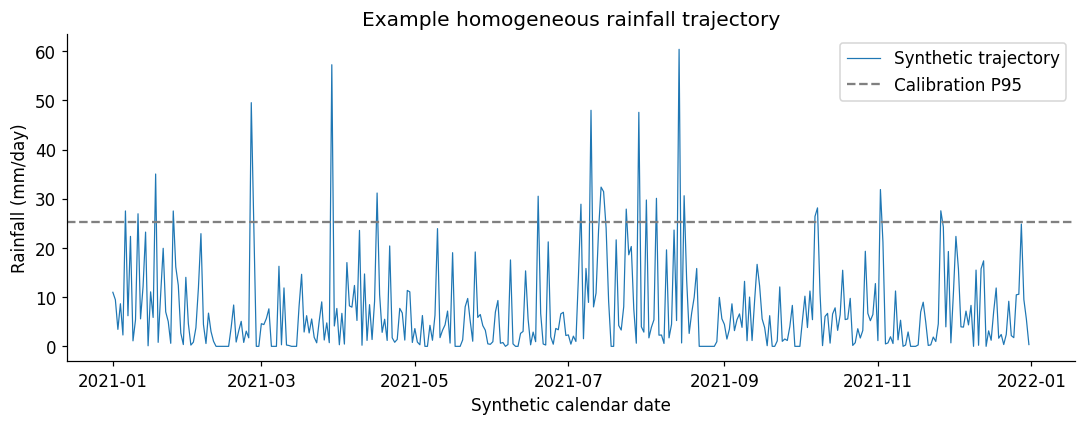

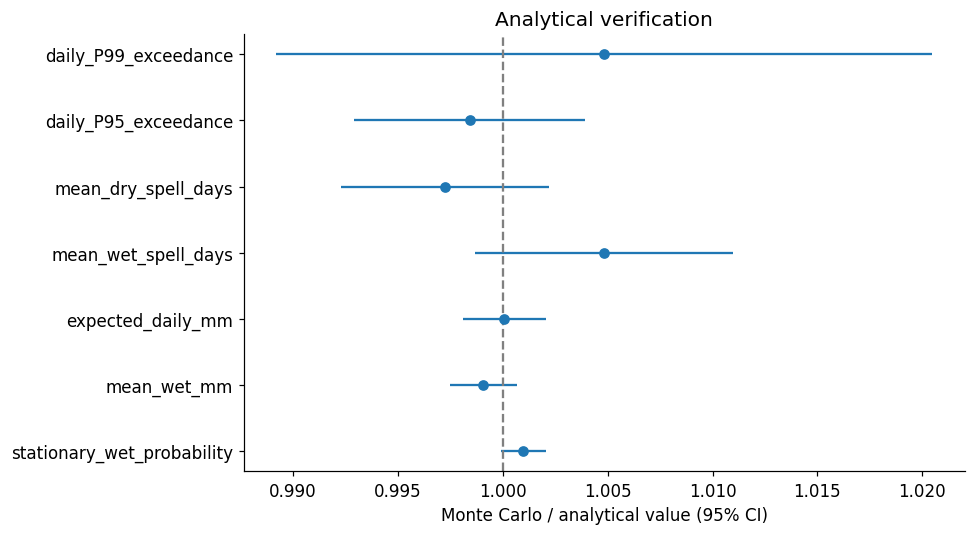

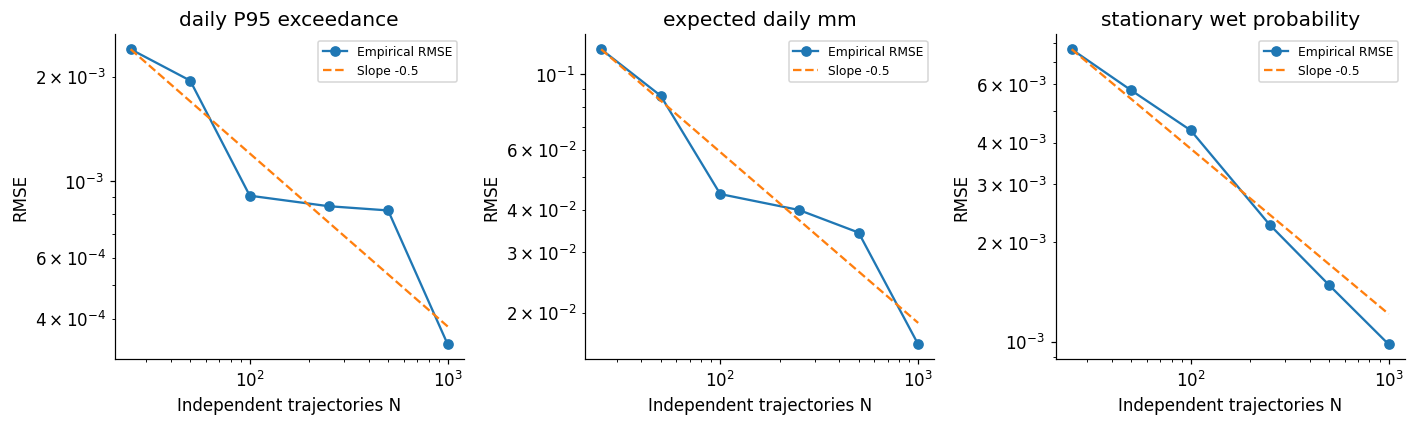

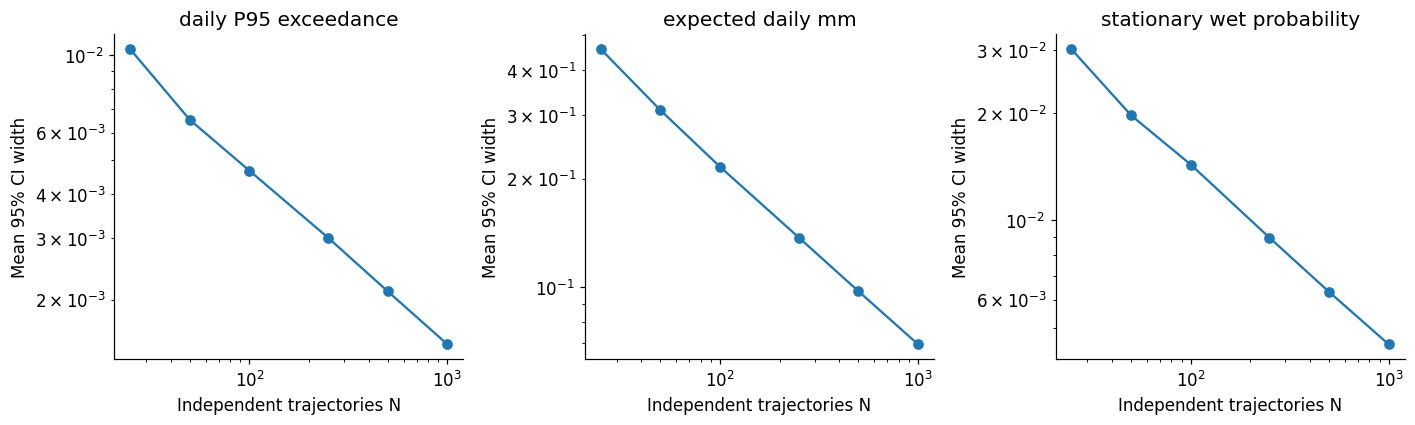

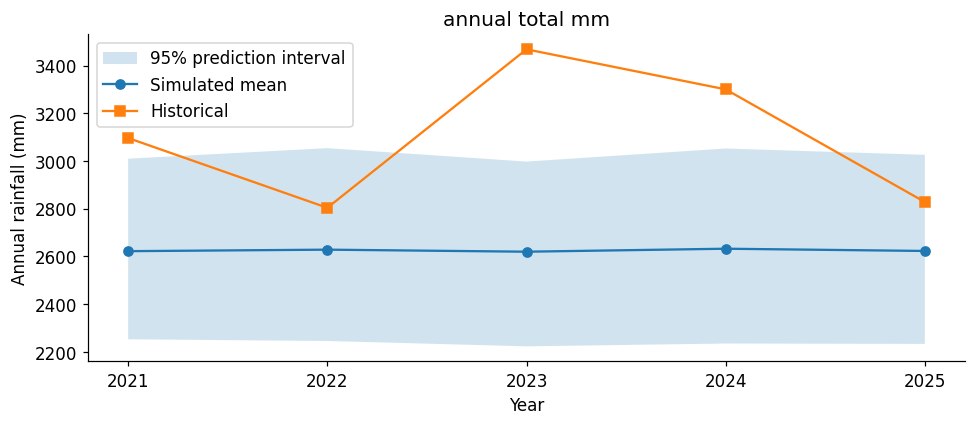

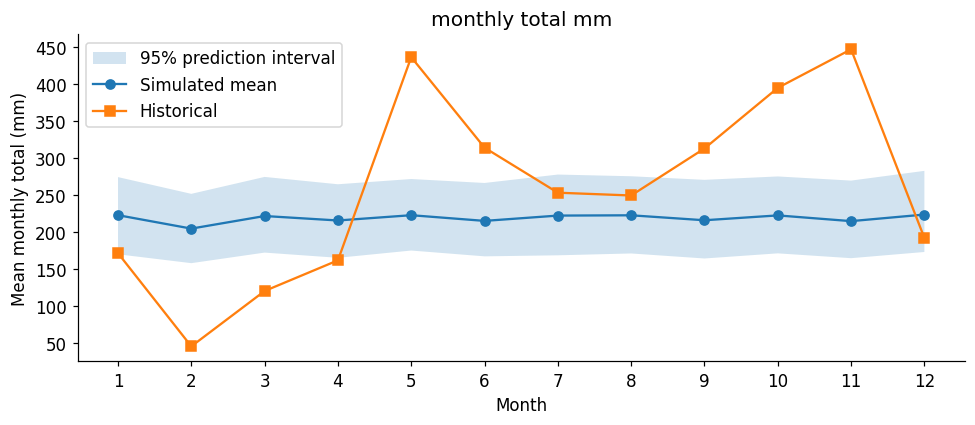

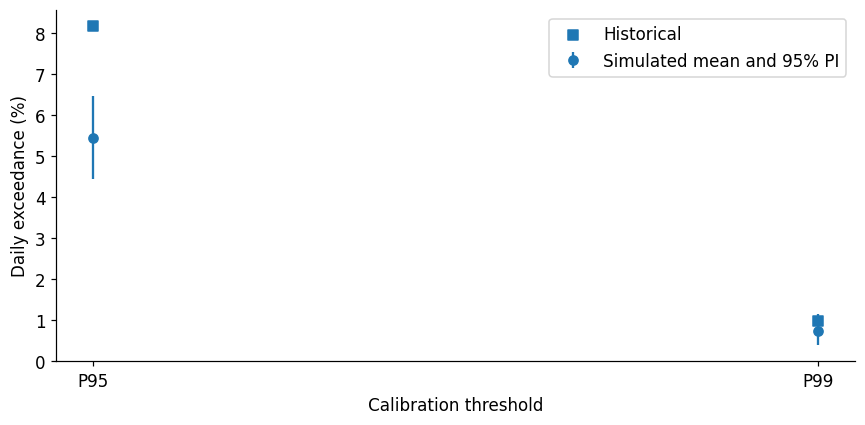

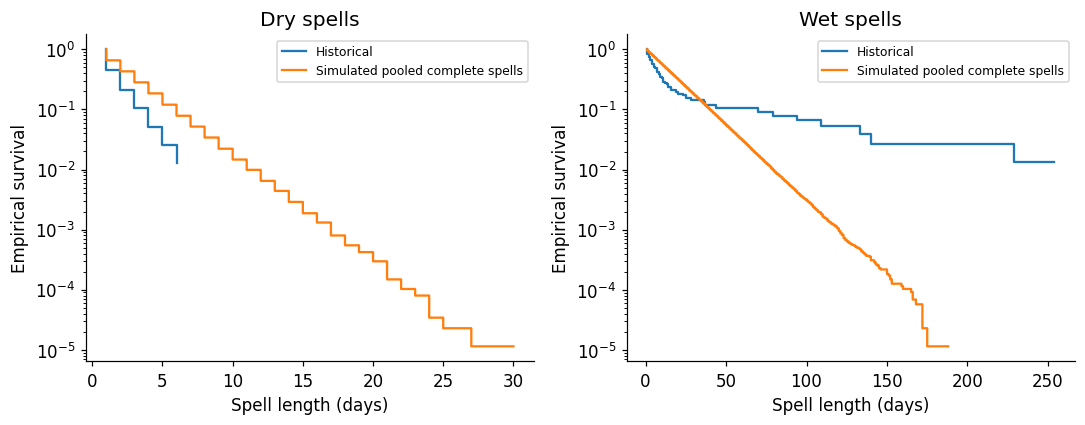

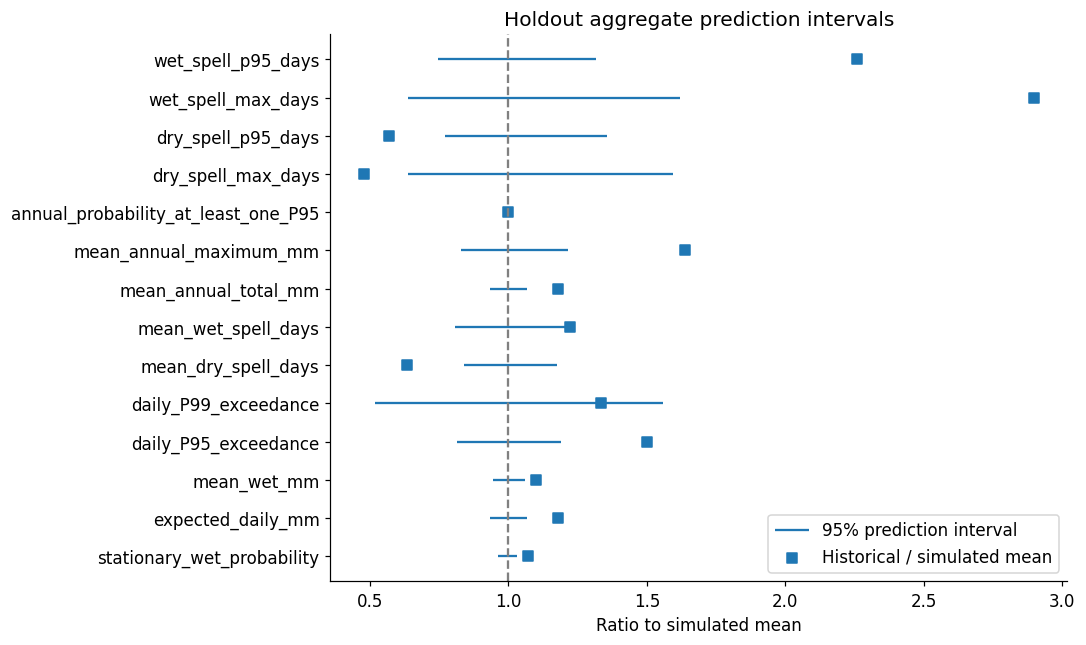

In [54]:
# C22
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(calendar[:365], hold_amounts[0, :365], lw=.8, label='Synthetic trajectory')
ax.axhline(q95, ls='--', color='gray', label='Calibration P95')
ax.set(
    xlabel='Synthetic calendar date',
    ylabel='Rainfall (mm/day)',
    title='Example homogeneous rainfall trajectory'
)
ax.legend()
finish(fig, 'F15_synthetic_trajectory')
fig, ax = plt.subplots(figsize=(9, 5))
ratios = analytical_mc['mean'] / analytical_mc.analytical
ax.errorbar(
    ratios,
    range(len(ratios)),
    xerr=[ratios - analytical_mc.ci_low / analytical_mc.analytical, analytical_mc.ci_high / analytical_mc.analytical - ratios],
    fmt='o'
)
ax.axvline(1, color='gray', ls='--')
ax.set(
    yticks=range(len(ratios)),
    yticklabels=analytical_mc.metric,
    xlabel='Monte Carlo / analytical value (95% CI)',
    title='Analytical verification'
)
finish(fig, 'F16_analytical_verification')
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, (metric, group) in zip(axs, convergence.groupby('metric')):
    nvals = group.replications.to_numpy()
    ax.loglog(nvals, group.rmse, 'o-', label='Empirical RMSE')
    ax.loglog(nvals, group.rmse.iloc[0] * (nvals / nvals[0])**-.5, '--', label='Slope -0.5')
    ax.set(xlabel='Independent trajectories N', ylabel='RMSE', title=metric.replace('_', ' '))
    ax.legend(fontsize=8)
finish(fig, 'F17_convergence')
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, (metric, group) in zip(axs, convergence.groupby('metric')):
    ax.loglog(group.replications, group.mean_ci_width, 'o-')
    ax.set(
        xlabel='Independent trajectories N',
        ylabel='Mean 95% CI width',
        title=metric.replace('_', ' ')
    )
finish(fig, 'F18_ci_width')

def comparison_plot(metric, filename, xlabel, ylabel):
    group = holdout[holdout.metric == metric]
    pos = np.arange(len(group))
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.fill_between(pos, group.pi_low, group.pi_high, alpha=.2, label='95% prediction interval')
    ax.plot(pos, group['mean'], 'o-', label='Simulated mean')
    ax.plot(pos, group.historical, 's-', label='Historical')
    ax.set(
        xticks=pos,
        xticklabels=group.group,
        xlabel=xlabel,
        ylabel=ylabel,
        title=metric.replace('_', ' ')
    )
    ax.legend()
    finish(fig, filename)
comparison_plot('annual_total_mm', 'F19_annual_holdout', 'Year', 'Annual rainfall (mm)')
comparison_plot('monthly_total_mm', 'F20_monthly_holdout', 'Month', 'Mean monthly total (mm)')
fig, ax = plt.subplots(figsize=(8, 4))
group = holdout[holdout.metric.isin(['daily_P95_exceedance', 'daily_P99_exceedance'])]
pos = np.arange(2)
ax.errorbar(
    pos,
    100 * group['mean'],
    yerr=[100 * (group['mean'] - group.pi_low), 100 * (group.pi_high - group['mean'])],
    fmt='o',
    label='Simulated mean and 95% PI'
)
ax.scatter(pos, 100 * group.historical, marker='s', label='Historical')
ax.set(
    xticks=pos,
    xticklabels=['P95', 'P99'],
    ylabel='Daily exceedance (%)',
    xlabel='Calibration threshold'
)
ax.legend()
finish(fig, 'F21_extreme_holdout')
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for state, ax in enumerate(axs):
    obs = complete_spells(observed_states[0], state)
    sim = np.concatenate([complete_spells(row, state) for row in hold_states])
    for values, label in [(obs, 'Historical'), (sim, 'Simulated pooled complete spells')]:
        sorted_values = np.sort(values)
        ax.step(sorted_values, 1 - np.arange(len(values)) / len(values), where='pre', label=label)
    ax.set(
        xlabel='Spell length (days)',
        ylabel='Empirical survival',
        yscale='log',
        title=['Dry spells', 'Wet spells'][state]
    )
    ax.legend(fontsize=8)
finish(fig, 'F22_spell_holdout')
fig, ax = plt.subplots(figsize=(10, 6))
group = holdout[(holdout.group == 'all') & (holdout['mean'] > 0)]
pos = np.arange(len(group))
ax.hlines(
    pos,
    group.pi_low / group['mean'],
    group.pi_high / group['mean'],
    label='95% prediction interval'
)
ax.scatter(group.historical / group['mean'], pos, marker='s', label='Historical / simulated mean')
ax.axvline(1, ls='--', color='gray')
ax.set(
    yticks=pos,
    yticklabels=group.metric,
    xlabel='Ratio to simulated mean',
    title='Holdout aggregate prediction intervals'
)
ax.legend()
finish(fig, 'F23_holdout_intervals')

**C23 · Record homogeneous experiment configuration and runtime.** Export the actual configuration, stream namespaces and runtime information, update figure primitives and the internal inventory, but do not publish a premature completion manifest.

In [55]:
# C23
(PROCESSED_DIR / 'simulation_config.json').write_text(json.dumps({
    **EXPERIMENT,
    'primary_threshold_mm': float(q95),
    'secondary_threshold_mm': float(q99),
    'holdout_initial_state': int(cal.is_wet.iloc[-1]),
    'stream_namespaces': {'tests': 0, 'verification': 1, 'convergence': 2, 'holdout': 3, 'annual': 4}
}, indent=2) + '\n')
new_files = {
    'C18': ['simulation_verification.csv'],
    'C19': ['monte_carlo_analytical.csv', 'annual_simulation_uncertainty.csv'],
    'C20': [
        'convergence_batches.csv',
        'convergence_results.csv',
        'convergence_slopes.csv',
        'convergence_timing.csv'
    ],
    'C21': [
        'holdout_comparison.csv',
        'holdout_trajectory_statistics.csv',
        'holdout_aggregate_errors.csv'
    ],
    'C23': ['simulation_config.json', 'execution_runtime.csv']
}
for cell, files in new_files.items():
    for filename in files:
        manifest.loc[len(manifest)]=[f'data/processed/{filename}',cell,filename.replace('_',' ')]
for name in FIGURE_DATA:
    if int(name[1:3]) >= 15:
        manifest.loc[len(manifest)]=[f'figures/{name}.png','C22',name.replace('_',' ')]
manifest.loc[manifest.path.str.endswith(('figure_data.json', 'output_manifest.csv')), 'cell'] = 'C23'
(PROCESSED_DIR / 'figure_data.json').write_text(json.dumps(FIGURE_DATA, default=str, sort_keys=True), encoding='utf-8')
pd.DataFrame([{
    'elapsed_seconds': time.perf_counter() - RUN_START,
    'python': platform.python_version(),
    'bootstrap_seconds': BOOTSTRAP_SECONDS,
    'execution_mode': EXECUTION_MODE
}]).to_csv(PROCESSED_DIR / 'execution_runtime.csv', index=False)
assert len(FIGURE_DATA) == 23 and manifest.path.is_unique and all((OUTPUT / path).is_file() for path in manifest.path if path != "data/processed/output_manifest.csv")
print('Complete pipeline:', len(manifest), 'outputs; seconds:', time.perf_counter() - RUN_START)

Complete pipeline: 52 outputs; seconds: 136.97725106600046


### Execution provenance

This readability revision preserves the scientific methods and executable statements. Run the notebook in one ordinary kernel, beginning with the pinned dependency installation. The final outputs include 32 figures at 300 DPI and 72 manifest entries. Previous results and reference values in the narrative are not calculation inputs.

The author reports independent Windows Python 3.14 and Google Colab execution of the frozen scientific workflow. Earlier Linux diagnostics used the available pandas 2.2.3 rather than the target pandas 2.3.3; those diagnostic results are not proof of exact-pin execution in every environment. Compare regenerated results with the frozen reference using the optional verifier, and record the actual loaded versions and execution completion.


### Seasonal model and controlled sensitivity

**Calendar-dependent occurrence.** The seasonal generator uses transition matrices $P_t$ selected by destination date and retains the previous state at every seasonal and annual boundary. With the row probability vector $\boldsymbol\pi_t$,

$$\boldsymbol\pi_t=\boldsymbol\pi_{t-1}P_t,\qquad E[R_t]=\pi_{t,1}m_{X,t},\qquad \Pr(R_t>u)=\pi_{t,1}\frac{\bar F_t(u)}{\bar F_t(\tau)}.$$

Horizon-average expectations are arithmetic means over the same chronological dates as simulation. The initial probability is determined by the explicit preceding-day state, not an annual stationary approximation. The existing exported key `stationary_wet_probability` is retained for compatible cross-model tables; **in seasonal outputs it means horizon-average wet-day probability, not stationarity**. C25 verifies this propagation and deterministic boundaries; C26–C27 compare equal calendar/trajectory configurations and use common random numbers across corresponding model replications. The seasonal extension was predefined; prior holdout findings are visible but not used for refitting.

**Controlled sensitivity.** For a relative odds multiplier $k$, update the selected transition probability by

$$p'=\frac{kp}{1-p+kp},\qquad p'_{i0}=1-p'_{i1}.$$

Gamma intensity changes by $\beta'=k_\beta\beta$; shape and fixed thresholds remain unchanged. Odds percentages are not percentage-point changes in probability. The experiment evaluates −20%, −10%, 0%, +10% and +20% one at a time for $p_{01}$, $p_{11}$ and $\beta$, and the full 5 × 5 persistence–intensity grid. It uses 500 independent 365-day trajectories per unique scenario, with shared uniform draws across comparable scenarios and cached intensity transforms for the five scale values. Replication units remain independent.

For the homogeneous stationary scenario, let $r=\Pr(X>u\mid X\geq\tau)$ and $A=P\operatorname{diag}(1,1-r)$. The probability of at least one event over $D$ days is

$$1-\boldsymbol\pi A^D\mathbf{1};\qquad E[C_D]=D\pi_1r.$$

This survival calculation accounts for occurrence dependence. Paired trajectory differences quantify simulation uncertainty in changes; annual-event marginals use exact binomial confidence intervals, and paired t intervals approximate uncertainty in differences. A degenerate binary interval is not certainty. These experiments change mathematical model parameters only; they are not climate projections or causal environmental interventions.


**C24 · Define the seasonal generator and analytical propagation.** Use destination-date parameter blocks while preserving chronological state. Match draw consumption with the homogeneous ensemble for paired comparisons and compute date-specific expectations independently.

In [56]:
# C24
S6 = dict(reps=EXPERIMENT['holdout_reps'], annual_days=365,
          multipliers=[0.8, 0.9, 1.0, 1.1, 1.2], sensitivity_reps=500)
season_models = {r['season']: (np.array([[r['p00'], r['p01']],
                                        [r['p10'], r['p11']]]),
                              r['shape'], r['scale_mm'], WET)
                 for r in seasonal_rows}


def calendar_ensemble(dates, reps: int, models: dict, initial: int,
                      seed: int = SEED, namespace: tuple = (3,)):
    """Use destination-date parameters and preserve state across boundaries.

    Matching seed/namespace pairs deliberately share occurrence and amount uniforms.
    Distinct child streams correspond to independent trajectories.
    """
    dates = pd.DatetimeIndex(dates)
    assert len(dates) and dates.equals(pd.date_range(dates[0], periods=len(dates)))
    assert initial in (0, 1) and reps > 0
    labels = np.array([season_map[m] for m in dates.month])
    for model in models.values():
        validate(*model)
    u = np.empty((reps, len(dates)))
    v = np.empty_like(u)
    for i, child in enumerate(np.random.SeedSequence(seed, spawn_key=namespace).spawn(reps)):
        generator = np.random.default_rng(child)
        # Consume the same origin draw as the homogeneous generator before the paired uniforms.
        generator.random()  # same origin draw consumption as homogeneous ensemble
        u[i] = generator.random(len(dates))
        v[i] = generator.random(len(dates))
    states = np.empty(u.shape, dtype=np.int8)
    previous = np.full(reps, initial, dtype=np.int8)
    for j, label in enumerate(labels):
        matrix = models[label][0]
        previous = (u[:, j] < matrix[previous, 1]).astype(np.int8)
        states[:, j] = previous
    amounts = np.zeros(u.shape)
    for label, (_, shape, scale, lower) in models.items():
        wet = (states == 1) & (labels == label)[None, :]
        amounts[wet] = sample_amounts(v[wet], shape, scale, lower)
    return states, amounts


def calendar_expectations(dates, models: dict, initial: int):
    """Propagate the probability vector; no annual stationary approximation."""
    probability = np.eye(2)[initial]
    rows = []
    for date in dates:
        matrix, shape, scale, lower = models[season_map[date.month]]
        probability = probability @ matrix
        denominator = gammaincc(shape, lower / scale)
        mean = shape * scale * gammaincc(shape + 1, lower / scale) / denominator
        rows.append([probability[1], probability[1] * mean,
                     probability[1] * gammaincc(shape, q95 / scale) / denominator,
                     probability[1] * gammaincc(shape, q99 / scale) / denominator])
    return pd.DataFrame(rows, index=dates, columns=['stationary_wet_probability',
        'expected_daily_mm', 'daily_P95_exceedance', 'daily_P99_exceedance'])

**C25 · Verify season classification, boundaries and analytical expectations.** Test all months, leap days, seasonal and annual continuity, homogeneous reduction and reproducibility; then compare four horizon-average expectations with a seasonal ensemble and export outcomes.

In [57]:
# C25
checks = []

def check(label, condition):
    assert condition, label
    checks.append(dict(test=label, passed=True))

check('All twelve months', [season_map[m] for m in range(1, 13)] ==
      ['NEM', 'NEM', 'FIM', 'FIM', 'SWM', 'SWM', 'SWM', 'SWM', 'SWM', 'SIM', 'SIM', 'NEM'])
check('Leap day NEM', season_map[pd.Timestamp('2024-02-29').month] == 'NEM')
for name, model in season_models.items():
    validate(*model)
    check(name + ' parameter domain', True)
origin = int(cal.is_wet.iloc[-1])
identical = {name: MODEL for name in seasons}
reduced = calendar_ensemble(calendar, S6['reps'], identical, origin)
check('Exact reduction to homogeneous occurrence', np.array_equal(reduced[0], hold_states))
check('Exact reduction to homogeneous amounts', np.array_equal(reduced[1], hold_amounts))
# Deterministic alternating transition across both seasonal and annual boundaries.
alternating = (np.array([[0., 1.], [1., 0.]]), alpha, beta, WET)
for start in ['2023-12-30', '2024-02-28', '2024-04-29', '2024-09-29']:
    dates = pd.date_range(start, periods=4)
    states, amounts = calendar_ensemble(dates, 2, {s: alternating for s in seasons}, 0)
    check('Continuity ' + start, np.array_equal(states, np.tile([1, 0, 1, 0], (2, 1))))
# Distinct destination matrices verify selection, not merely continuity.
forced = {s: (np.array([[1., 0.], [1., 0.]]), alpha, beta, WET) for s in seasons}
forced['FIM'] = (np.array([[0., 1.], [0., 1.]]), alpha, beta, WET)
check('Destination season switch', np.array_equal(calendar_ensemble(pd.date_range('2024-02-28', periods=4), 1, forced, 1)[0], [[0, 0, 1, 1]]))
season_states, season_amounts = calendar_ensemble(calendar, S6['reps'], season_models, origin)
check('Dry rainfall zero', np.all(season_amounts[season_states == 0] == 0))
check('Wet support', np.all(season_amounts[season_states == 1] >= WET))
repeat = calendar_ensemble(calendar, S6['reps'], season_models, origin)
check('Same seed reproducibility', np.array_equal(repeat[1], season_amounts))
del repeat, reduced
season_stats = trajectory_stats(season_states, season_amounts, q95, q99)
expected = calendar_expectations(calendar, season_models, origin)
expected.to_csv(PROCESSED_DIR / 'seasonal_daily_expectations.csv', index_label='date')
season_verify = []
for metric, target in expected.mean().items():
    result = uncertainty(season_stats[metric])
    error = abs(result['mean'] - target)
    tolerance = EXPERIMENT['sigma'] * result['mcse'] + ATOL
    season_verify.append(dict(
        metric=metric,
        analytical=target,
        **result,
        absolute_error=error,
        tolerance=tolerance,
        passed=error <= tolerance
    ))
    check('Analytical ' + metric, error <= tolerance)
season_verify = pd.DataFrame(season_verify)
season_verify.to_csv(PROCESSED_DIR / 'seasonal_analytical.csv', index=False)
pd.DataFrame(checks).to_csv(PROCESSED_DIR / 'seasonal_verification.csv', index=False)
display(season_verify, pd.DataFrame(checks))

,metric,analytical,n,mean,mcse,ci_low,ci_high,pi_low,pi_high,absolute_error,tolerance,passed
0,stationary_wet_probability,0.860800,1000,0.861053,0.000382,0.860303,0.861802,0.837349,0.883352,0.000252,0.001528,True
1,expected_daily_mm,7.189990,1000,7.184172,0.007198,7.170047,7.198297,6.728688,7.627754,0.005818,0.028793,True
2,daily_P95_exceedance,0.051428,1000,0.051405,0.000168,0.051075,0.051735,0.041621,0.062432,0.000023,0.000673,True
3,daily_P99_exceedance,0.008166,1000,0.008199,0.000064,0.008073,0.008326,0.004381,0.012596,0.000033,0.000257,True


,test,passed
0,All twelve months,True
1,Leap day NEM,True
2,NEM parameter domain,True
3,FIM parameter domain,True
4,SWM parameter domain,True
5,SIM parameter domain,True
6,Exact reduction to homogeneous occurrence,True
7,Exact reduction to homogeneous amounts,True
8,Continuity 2023-12-30,True
9,Continuity 2024-02-28,True


**C26 · Evaluate the seasonal model on the same holdout.** Reuse the homogeneous aggregation logic, calendar and preceding state. Common random numbers pair corresponding trajectories while preserving independence across replication units.

In [58]:
# C26
# Reuse the exact S005 aggregation logic with seasonal arrays, retaining baseline outputs.

def seasonal_comparison():
    hold_rows = []
    def compare(metric, group, actual, simulated):
        result = uncertainty(simulated)
        hold_rows.append(dict(
            metric=metric,
            group=str(group),
            historical=float(actual),
            **result,
            absolute_error=abs(result['mean'] - actual),
            relative_error=abs(result['mean'] - actual) / abs(actual) if actual else np.nan,
            inside_pi=result['pi_low'] <= actual <= result['pi_high']
        ))
    for metric in season_stats:
        compare(metric, 'all', observed_stats[metric].iloc[0], season_stats[metric])
    years = calendar.year.unique()
    annual_sim = []
    annual_obs = []
    maxima_sim = []
    maxima_obs = []
    events_sim = []
    events_obs = []
    for year in years:
        mask = calendar.year == year
        totals = season_amounts[:, mask].sum(axis=1)
        actual = observed_amounts[:, mask].sum()
        maxima = season_amounts[:, mask].max(axis=1)
        actual_max = observed_amounts[:, mask].max()
        event = (season_amounts[:, mask] > q95).any(axis=1)
        actual_event = (observed_amounts[:, mask] > q95).any()
        annual_sim.append(totals)
        annual_obs.append(actual)
        maxima_sim.append(maxima)
        maxima_obs.append(actual_max)
        events_sim.append(event)
        events_obs.append(actual_event)
        compare('annual_total_mm', year, actual, totals)
        compare('annual_maximum_mm', year, actual_max, maxima)
        compare('annual_probability_at_least_one_P95', year, actual_event, event)
        interval = stats.binomtest(int(event.sum()), len(event)).proportion_ci(confidence_level=EXPERIMENT['confidence'], method='exact')
        hold_rows[-1].update(ci_low=interval.low, ci_high=interval.high, ci_method='exact binomial')
    compare('mean_annual_total_mm', 'all', np.mean(annual_obs), np.mean(annual_sim, axis=0))
    compare('mean_annual_maximum_mm', 'all', np.mean(maxima_obs), np.mean(maxima_sim, axis=0))
    compare(
        'annual_probability_at_least_one_P95',
        'all',
        np.mean(events_obs),
        np.mean(events_sim, axis=0)
    )
    for month in range(1, 13):
        masks = [(calendar.month == month) & (calendar.year == year) for year in years]
        compare(
            'monthly_total_mm',
            month,
            np.mean([observed_amounts[:, m].sum() for m in masks]),
            np.mean([season_amounts[:, m].sum(axis=1) for m in masks], axis=0)
        )
    for season in seasons:
        mask = evaluation.season.to_numpy() == season
        for metric, actual, simulated in [
            ('season_daily_mm', observed_amounts[:, mask].mean(), season_amounts[:, mask].mean(axis=1)),
            (
                'season_wet_frequency',
                observed_states[:, mask].mean(),
                season_states[:, mask].mean(axis=1)
            ),
            (
                'season_P95_frequency',
                (observed_amounts[:, mask] > q95).mean(),
                (season_amounts[:, mask] > q95).mean(axis=1)
            ),
            (
                'season_P99_frequency',
                (observed_amounts[:, mask] > q99).mean(),
                (season_amounts[:, mask] > q99).mean(axis=1)
            )
        ]:
            compare(metric, season, actual, simulated)
    for state, label in [(0, 'dry'), (1, 'wet')]:
        empirical_runs = complete_spells(observed_states[0], state)
        simulated_runs = [complete_spells(row, state) for row in season_states]
        for statistic, function in [('max', np.max), ('p95', lambda a: np.quantile(a, .95))]:
            compare(f'{label}_spell_{statistic}_days','all',function(empirical_runs),np.array([function(run) if len(run) else np.nan for run in simulated_runs]))
    holdout = pd.DataFrame(hold_rows)
    holdout.to_csv(PROCESSED_DIR / 'seasonal_holdout.csv', index=False)
    aggregate_errors = pd.DataFrame([dict(
        metric=label,
        mae=np.mean(abs(g.historical - g['mean'])),
        rmse=np.sqrt(np.mean((g.historical - g['mean'])**2))
    ) for label, g in holdout[holdout.metric.isin(['monthly_total_mm', 'season_daily_mm'])].groupby('metric')])
    display(holdout, aggregate_errors)
    return holdout, aggregate_errors
seasonal_holdout, seasonal_errors = seasonal_comparison()

,metric,group,historical,n,mean,mcse,ci_low,ci_high,pi_low,pi_high,absolute_error,relative_error,inside_pi,ci_method
0,stationary_wet_probability,all,0.922234,1000,0.861053,0.000382,0.860303,0.861802,0.837349,0.883352,0.061182,0.066341,False,NaN
1,expected_daily_mm,all,8.486637,1000,7.184172,0.007198,7.170047,7.198297,6.728688,7.627754,1.302466,0.153473,False,NaN
2,mean_wet_mm,all,9.202257,1000,8.343626,0.007656,8.328601,8.358650,7.862749,8.805083,0.858631,0.093307,False,NaN
3,daily_P95_exceedance,all,0.081599,1000,0.051405,0.000168,0.051075,0.051735,0.041621,0.062432,0.030194,0.370027,False,NaN
4,daily_P99_exceedance,all,0.009858,1000,0.008199,0.000064,0.008073,0.008326,0.004381,0.012596,0.001658,0.168222,True,NaN
5,mean_dry_spell_days,all,1.844156,1000,2.854600,0.008110,2.838686,2.870514,2.376172,3.390488,1.010444,0.547917,False,NaN
6,mean_wet_spell_days,all,21.855263,1000,17.914701,0.050151,17.816287,18.013114,14.932659,21.160392,3.940563,0.180303,False,NaN
7,annual_total_mm,2021,3096.300000,1000,2624.778274,5.672256,2613.647371,2635.909177,2295.462708,2992.661944,471.521726,0.152286,False,NaN
8,annual_maximum_mm,2021,108.500000,1000,69.907487,0.596126,68.737685,71.077289,43.939072,116.256769,38.592513,0.355691,True,NaN
9,annual_probability_at_least_one_P95,2021,1.000000,1000,1.000000,0.000000,0.996318,1.000000,1.000000,1.000000,0.000000,0.000000,True,exact binomial


,metric,mae,rmse
0,monthly_total_mm,57.428592,73.479345
1,season_daily_mm,1.390144,1.510139


**C27 · Compare historical realism and paired model differences.** Join model summaries, calculate like-for-like monthly/seasonal errors and percentage changes from the homogeneous baseline. Paired differences describe Monte Carlo variation, not a causal intervention.

In [59]:
# C27
# Paired aggregate comparisons use identical random inputs per trajectory.
comparative = pd.concat([holdout.assign(model='homogeneous'), seasonal_holdout.assign(model='seasonal')], ignore_index=True)
comparative.to_csv(PROCESSED_DIR / 'comparative_holdout.csv', index=False)
errors = pd.concat([aggregate_errors.assign(model='homogeneous'), seasonal_errors.assign(model='seasonal')], ignore_index=True)
for metric in ['season_P95_frequency', 'season_P99_frequency', 'season_wet_frequency']:
    for model, group in comparative[comparative.metric == metric].groupby('model'):
        delta = group['mean'] - group.historical
        errors.loc[len(errors)] = [metric, np.mean(abs(delta)), np.sqrt(np.mean(delta**2)), model]
# Percentage changes use the homogeneous error as denominator for each matching metric.
base_errors = errors[errors.model == 'homogeneous'].set_index('metric')
for measure in ['mae', 'rmse']:
    errors[measure + '_change_pct'] = [100 * (row[measure] / base_errors.loc[row.metric, measure] - 1) for _, row in errors.iterrows()]
errors.to_csv(PROCESSED_DIR / 'comparative_errors.csv', index=False)
paired = []
for metric in hold_stats:
    paired.append(dict(metric=metric, **uncertainty(season_stats[metric] - hold_stats[metric])))
pd.DataFrame(paired).to_csv(PROCESSED_DIR / 'comparative_paired.csv', index=False)
display(errors, comparative[comparative.group == 'all'])

,metric,mae,rmse,model,mae_change_pct,rmse_change_pct
0,monthly_total_mm,105.719306,126.525436,homogeneous,0.000000,0.000000
1,season_daily_mm,3.727141,4.090769,homogeneous,0.000000,0.000000
2,monthly_total_mm,57.428592,73.479345,seasonal,-45.678236,-41.925239
3,season_daily_mm,1.390144,1.510139,seasonal,-62.702135,-63.084216
4,season_P95_frequency,0.058641,0.066153,homogeneous,0.000000,0.000000
5,season_P95_frequency,0.027719,0.037138,seasonal,-52.730594,-43.861325
6,season_P99_frequency,0.007369,0.008830,homogeneous,0.000000,0.000000
7,season_P99_frequency,0.005368,0.006658,seasonal,-27.156663,-24.598500
8,season_wet_frequency,0.100055,0.102370,homogeneous,0.000000,0.000000
9,season_wet_frequency,0.067201,0.100901,seasonal,-32.835364,-1.434988


,metric,group,historical,n,mean,mcse,ci_low,ci_high,pi_low,pi_high,absolute_error,relative_error,inside_pi,ci_method,model
0,stationary_wet_probability,all,0.922234,1000,0.860408,0.000503,0.859421,0.861395,0.826930,0.888280,0.061826,0.067040,False,NaN,homogeneous
1,expected_daily_mm,all,8.486637,1000,7.187763,0.007949,7.172164,7.203363,6.701484,7.665457,1.298874,0.153049,False,NaN,homogeneous
2,mean_wet_mm,all,9.202257,1000,8.353910,0.007851,8.338504,8.369316,7.882894,8.844488,0.848346,0.092189,False,NaN,homogeneous
3,daily_P95_exceedance,all,0.081599,1000,0.054338,0.000168,0.054008,0.054669,0.044359,0.064622,0.027261,0.334081,False,NaN,homogeneous
4,daily_P99_exceedance,all,0.009858,1000,0.007386,0.000064,0.007260,0.007512,0.003834,0.011501,0.002472,0.250722,True,NaN,homogeneous
5,mean_dry_spell_days,all,1.844156,1000,2.907323,0.007895,2.891830,2.922816,2.445721,3.416693,1.063167,0.576506,False,NaN,homogeneous
6,mean_wet_spell_days,all,21.855263,1000,17.889937,0.059484,17.773210,18.006665,14.460082,21.929602,3.965326,0.181436,True,NaN,homogeneous
22,mean_annual_total_mm,all,3099.320000,1000,2624.971097,2.903156,2619.274113,2630.668081,2447.381784,2799.424770,474.348903,0.153049,False,NaN,homogeneous
23,mean_annual_maximum_mm,all,103.620000,1000,63.215782,0.200983,62.821384,63.610179,52.437928,76.830107,40.404218,0.389927,False,NaN,homogeneous
24,annual_probability_at_least_one_P95,all,1.000000,1000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,True,NaN,homogeneous


**C28 · Evaluate the predefined sensitivity scenarios.** Perturb odds or Gamma scale independently and jointly; keep the original thresholds. Reuse common uniforms, compute analytical daily and annual risk, and export 400 rows of estimates, intervals and paired changes.

In [60]:
# C28

def odds_scale(p: float, multiplier: float) -> float:
    """Scale odds, not probability or percentage points."""
    return multiplier * p / (1 - p + multiplier * p)


def scenario_model(k01: float, k11: float, kb: float):
    # Copy the baseline before perturbing its odds and recomputing the row complements.
    matrix = P.copy()
    for i, k in enumerate([k01, k11]):
        matrix[i, 1] = odds_scale(P[i, 1], k)
        matrix[i, 0] = 1 - matrix[i, 1]
    return matrix, alpha, beta * kb, WET


def scenario_expectations(model, days: int):
    """Stationary marginal risk and exact annual event probability via survival recursion."""
    matrix, shape, scale, lower = model
    prob = stationary(matrix)
    denominator = gammaincc(shape, lower / scale)
    mean = shape * scale * gammaincc(shape + 1, lower / scale) / denominator
    results = {'stationary_wet_probability': prob[1], 'expected_daily_mm': prob[1] * mean,
             'mean_wet_mm': mean, 'mean_wet_spell_days': 1 / matrix[1, 0]}
    for label, threshold in [('P95', q95), ('P99', q99)]:
        tail = gammaincc(shape, threshold / scale) / denominator
        risk = prob[1] * tail
        # The substochastic matrix propagates the probability of no exceedance, retaining occurrence dependence.
        survival = prob @ np.linalg.matrix_power(matrix @ np.diag([1, 1 - tail]), days)
        results.update({f'daily_{label}_exceedance':risk,
                        f'annual_count_{label}':days*risk,
                        f'annual_event_{label}':1-survival.sum()})
    return results


# Cache common uniform draws and the five possible intensity transformations.
# Each scenario still uses its own stationary origin probability.
sensitivity_u = np.empty((S6['sensitivity_reps'], S6['annual_days']))
sensitivity_v = np.empty_like(sensitivity_u)
sensitivity_origins = np.empty(S6['sensitivity_reps'])
for i, child in enumerate(np.random.SeedSequence(SEED, spawn_key=(6,)).spawn(S6['sensitivity_reps'])):
    generator = np.random.default_rng(child)
    sensitivity_origins[i] = generator.random()
    sensitivity_u[i] = generator.random(S6['annual_days'])
    sensitivity_v[i] = generator.random(S6['annual_days'])
amount_cache = {}


def scenario_statistics(model):
    matrix, shape, scale, lower = model
    origins = (sensitivity_origins < stationary(matrix)[1]).astype(np.int8)
    states = generate_states(matrix, sensitivity_u, origins)
    if scale not in amount_cache:
        amount_cache[scale] = sample_amounts(sensitivity_v, shape, scale, lower)
    amounts = np.where(states == 1, amount_cache[scale], 0.)
    result = trajectory_stats(states, amounts, q95, q99)
    for label, threshold in [('P95', q95), ('P99', q99)]:
        result[f'annual_count_{label}']=(amounts>threshold).sum(axis=1)
        result[f'annual_event_{label}']=(amounts>threshold).any(axis=1).astype(float)
    return result

baseline_scenario = scenario_statistics(MODEL)
baseline_theory = scenario_expectations(MODEL, S6['annual_days'])
scenario_rows = []
settings = []
for axis in ['p01', 'p11', 'beta']:
    for k in S6['multipliers']:
        settings.append((
            axis,
            k if axis == 'p01' else 1.,
            k if axis == 'p11' else 1.,
            k if axis == 'beta' else 1.
        ))
for k11 in S6['multipliers']:
    for kb in S6['multipliers']:
        settings.append(('joint', 1., k11, kb))
cache = { (1., 1., 1.): baseline_scenario }
for axis, k01, k11, kb in settings:
    model = scenario_model(k01, k11, kb)
    validate(*model)
    key = (k01, k11, kb)
    if key not in cache:
        cache[key] = scenario_statistics(model)
    values = cache[key]
    theory = scenario_expectations(model, S6['annual_days'])
    for metric, target in theory.items():
        result = uncertainty(values[metric])
        paired_values = values[metric] - baseline_scenario[metric]
        difference = uncertainty(paired_values)
        if metric.startswith('annual_event'):
            interval = stats.binomtest(int(values[metric].sum()), len(values)).proportion_ci(method='exact')
            result.update(ci_low=interval.low, ci_high=interval.high)
        scenario_rows.append(dict(
            axis=axis,
            k01=k01,
            k11=k11,
            kbeta=kb,
            p01=model[0][0, 1],
            p11=model[0][1, 1],
            beta_mm=model[2],
            metric=metric,
            analytical=target,
            analytical_delta=target - baseline_theory[metric],
            analytical_relative_pct=100 * (target / baseline_theory[metric] - 1),
            **result,
            paired_delta=difference['mean'],
            paired_relative_pct=100 * difference['mean'] / baseline_scenario[metric].mean(),
            paired_ci_low=difference['ci_low'],
            paired_ci_high=difference['ci_high'],
            paired_n=difference['n']
        ))
sensitivity = pd.DataFrame(scenario_rows)
sensitivity.to_csv(PROCESSED_DIR / 'sensitivity_scenarios.csv', index=False)
display(sensitivity[(sensitivity.metric == 'daily_P95_exceedance') & (sensitivity.axis != 'joint')])

,axis,k01,k11,kbeta,p01,p11,beta_mm,metric,analytical,analytical_delta,...,mcse,ci_low,ci_high,pi_low,pi_high,paired_delta,paired_relative_pct,paired_ci_low,paired_ci_high,paired_n
4,p01,0.8,1.0,1.0,0.295923,0.943967,11.343818,daily_P95_exceedance,0.053262,-0.001221,...,0.000511,0.052027,0.054034,0.032877,0.073973,-0.001249,-2.301635,-0.001420,-0.001078,500
14,p01,0.9,1.0,1.0,0.321038,0.943967,11.343818,daily_P95_exceedance,0.053933,-0.000550,...,0.000512,0.052704,0.054715,0.032877,0.076712,-0.000570,-1.049869,-0.000689,-0.000451,500
24,p01,1.0,1.0,1.0,0.344423,0.943967,11.343818,daily_P95_exceedance,0.054483,0.000000,...,0.000512,0.053274,0.055285,0.032877,0.076712,0.000000,0.000000,0.000000,0.000000,500
34,p01,1.1,1.0,1.0,0.366250,0.943967,11.343818,daily_P95_exceedance,0.054941,0.000458,...,0.000510,0.053694,0.055698,0.034178,0.076712,0.000416,0.767212,0.000321,0.000512,500
44,p01,1.2,1.0,1.0,0.386672,0.943967,11.343818,daily_P95_exceedance,0.055329,0.000846,...,0.000512,0.054052,0.056063,0.035616,0.076712,0.000778,1.433475,0.000639,0.000918,500
54,p11,1.0,0.8,1.0,0.344423,0.930926,11.343818,daily_P95_exceedance,0.052765,-0.001718,...,0.000513,0.051694,0.053709,0.032877,0.076712,-0.001578,-2.907329,-0.001768,-0.001388,500
64,p11,1.0,0.9,1.0,0.344423,0.938126,11.343818,daily_P95_exceedance,0.053700,-0.000783,...,0.000510,0.052554,0.054558,0.032877,0.076712,-0.000723,-1.332526,-0.000858,-0.000588,500
74,p11,1.0,1.0,1.0,0.344423,0.943967,11.343818,daily_P95_exceedance,0.054483,0.000000,...,0.000512,0.053274,0.055285,0.032877,0.076712,0.000000,0.000000,0.000000,0.000000,500
84,p11,1.0,1.1,1.0,0.344423,0.948800,11.343818,daily_P95_exceedance,0.055149,0.000666,...,0.000511,0.053917,0.055924,0.035616,0.076712,0.000641,1.181102,0.000507,0.000776,500
94,p11,1.0,1.2,1.0,0.344423,0.952866,11.343818,daily_P95_exceedance,0.055721,0.001238,...,0.000515,0.054473,0.056497,0.035616,0.076712,0.001205,2.220876,0.001011,0.001400,500


**C29 · Generate seasonal and sensitivity figures F24–F32.** Show time-dependent verification, comparative climatology and spell behaviour, aggregate errors, sensitivity curves, joint heatmap and paired risk changes from actual results.

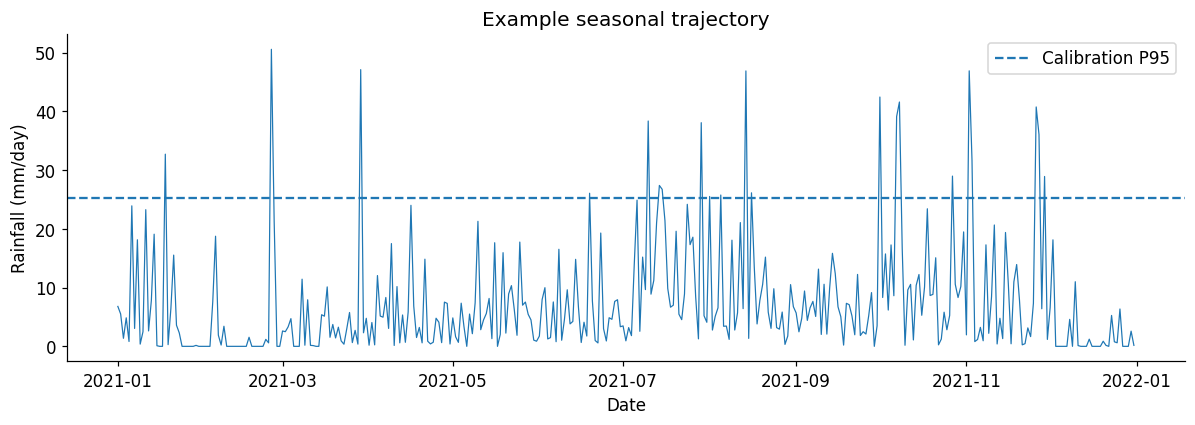

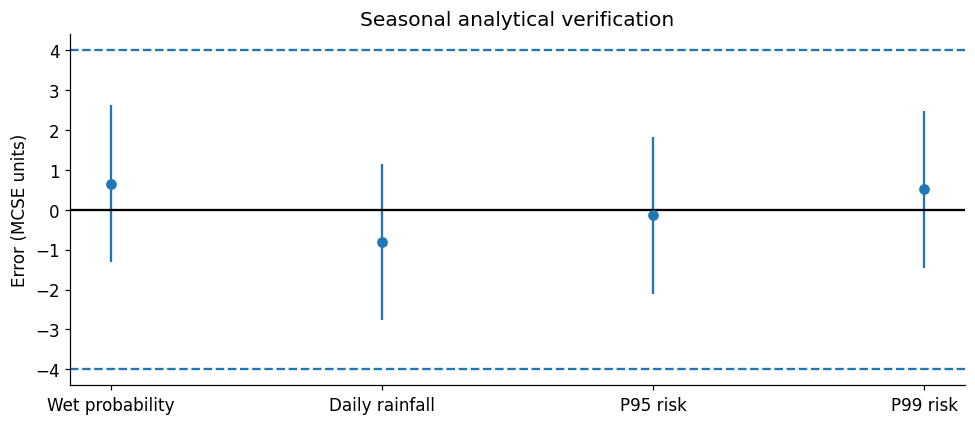

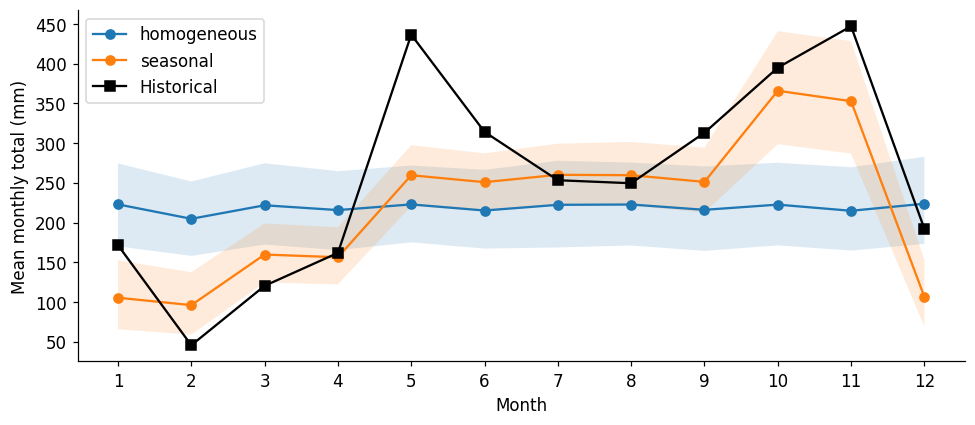

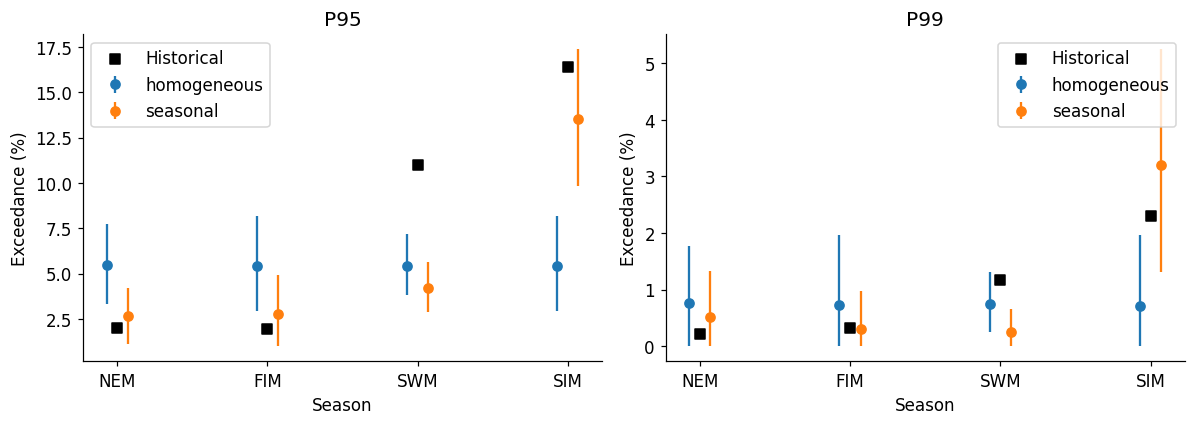

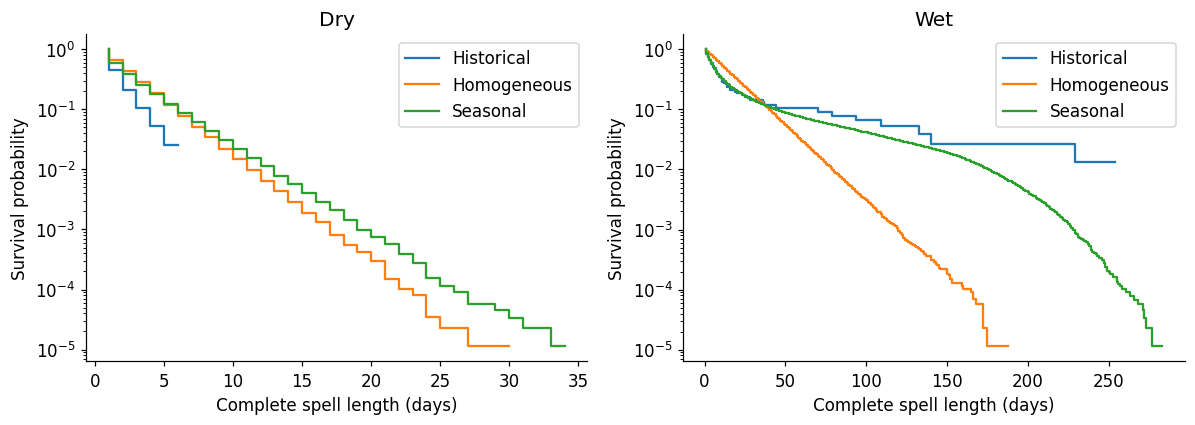

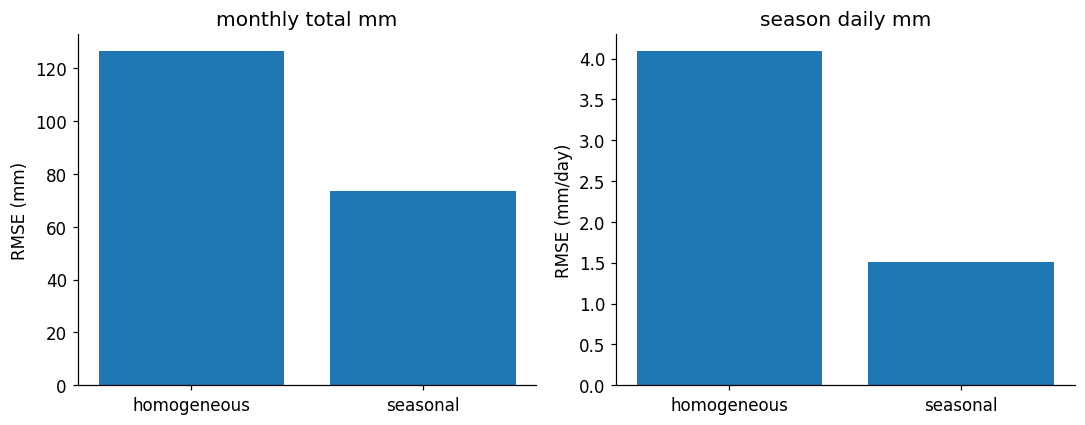

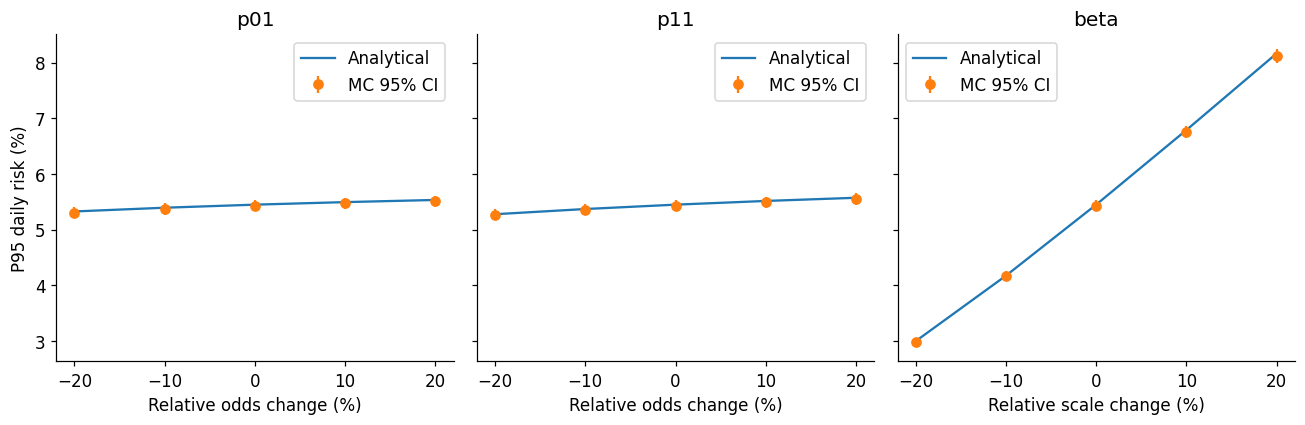

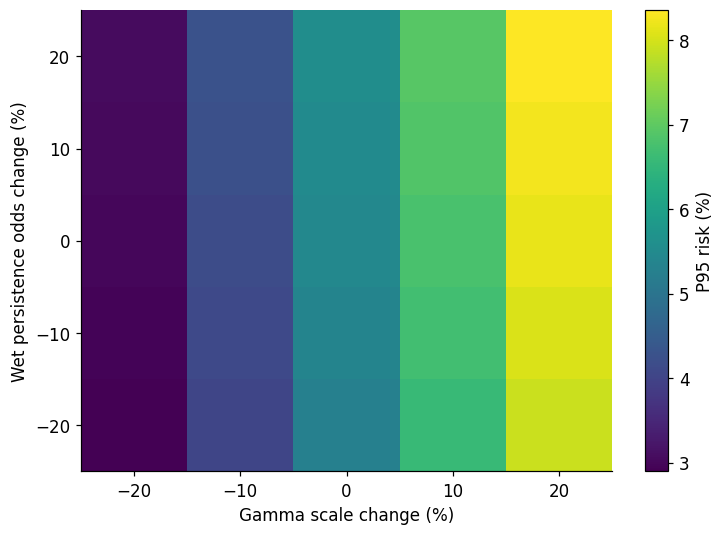

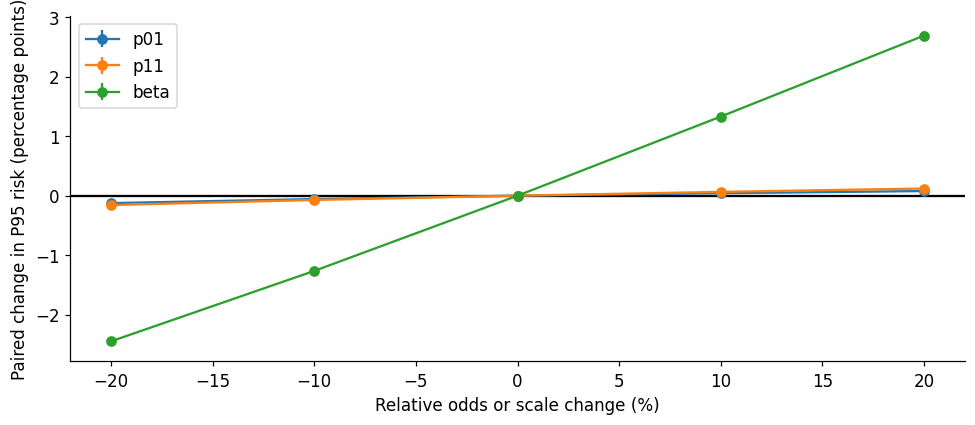

In [61]:
# C29
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(calendar[:365], season_amounts[0, :365], lw=.8)
ax.axhline(q95, ls='--', label='Calibration P95')
ax.set(xlabel='Date', ylabel='Rainfall (mm/day)', title='Example seasonal trajectory'); ax.legend()
finish(fig, 'F24_seasonal_trajectory')
fig, ax = plt.subplots(figsize=(9, 4))
ratio = (season_verify['mean'] - season_verify.analytical) / season_verify.mcse
ax.errorbar(range(len(ratio)), ratio, yerr=1.96, fmt='o'); ax.axhline(0, color='black'); ax.axhline(4, ls='--'); ax.axhline(-4, ls='--')
ax.set(
    xticks=range(4),
    xticklabels=['Wet probability', 'Daily rainfall', 'P95 risk', 'P99 risk'],
    ylabel='Error (MCSE units)',
    title='Seasonal analytical verification'
)
finish(fig, 'F25_seasonal_verification')
fig, ax = plt.subplots(figsize=(9, 4))
for model, group in comparative[comparative.metric == 'monthly_total_mm'].groupby('model'):
    x = group.group.astype(int).to_numpy(); ax.plot(x, group['mean'], marker='o', label=model); ax.fill_between(x, group.pi_low, group.pi_high, alpha=.15)
ax.plot(
    x,
    group.historical,
    color='black',
    marker='s',
    label='Historical'
); ax.set(xticks=range(1, 13), xlabel='Month', ylabel='Mean monthly total (mm)'); ax.legend()
finish(fig, 'F26_comparative_monthly')
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axs, ['season_P95_frequency', 'season_P99_frequency']):
    for i, (model, g) in enumerate(comparative[comparative.metric == metric].groupby('model')):
        ax.errorbar(
            np.arange(4) + (i - .5) * .14,
            g['mean'] * 100,
            yerr=[(g['mean'] - g.pi_low) * 100, (g.pi_high - g['mean']) * 100],
            fmt='o',
            label=model
        )
    ax.scatter(range(4), g.historical * 100, marker='s', color='black', label='Historical'); ax.set(
        xticks=range(4),
        xticklabels=seasons,
        ylabel='Exceedance (%)',
        xlabel='Season',
        title=metric.split('_')[1]
    ); ax.legend()
finish(fig, 'F27_comparative_seasonal_extremes')
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for state, ax in enumerate(axs):
    for label, array in [
        ('Historical', observed_states),
        ('Homogeneous', hold_states),
        ('Seasonal', season_states)
    ]:
        runs = np.concatenate([complete_spells(row, state) for row in array]); x = np.arange(1, runs.max() + 1); y = np.array([(runs >= k).mean() for k in x]); ax.step(x, y, label=label)
    ax.set(
        yscale='log',
        xlabel='Complete spell length (days)',
        ylabel='Survival probability',
        title=['Dry', 'Wet'][state]
    ); ax.legend()
finish(fig, 'F28_comparative_spells')
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric in zip(axs, ['monthly_total_mm', 'season_daily_mm']):
    g = errors[errors.metric == metric]; ax.bar(g.model, g.rmse); ax.set(ylabel='RMSE (mm)' if metric == 'monthly_total_mm' else 'RMSE (mm/day)', title=metric.replace('_', ' '))
finish(fig, 'F29_comparative_errors')
fig, axs = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, axis, col in zip(axs, ['p01', 'p11', 'beta'], ['k01', 'k11', 'kbeta']):
    g = sensitivity[(sensitivity.axis == axis) & (sensitivity.metric == 'daily_P95_exceedance')]; x = (g[col] - 1) * 100
    ax.plot(x, g.analytical * 100, label='Analytical'); ax.errorbar(
        x,
        g['mean'] * 100,
        yerr=[(g['mean'] - g.ci_low) * 100, (g.ci_high - g['mean']) * 100],
        fmt='o',
        label='MC 95% CI'
    ); ax.set(xlabel='Relative ' + ('scale' if axis == 'beta' else 'odds') + ' change (%)', title=axis); ax.legend()
axs[0].set_ylabel('P95 daily risk (%)'); finish(fig, 'F30_sensitivity_curves')
fig, ax = plt.subplots(figsize=(7, 5)); grid = sensitivity[(sensitivity.axis == 'joint') & (sensitivity.metric == 'daily_P95_exceedance')].pivot(index='k11', columns='kbeta', values='analytical') * 100
im = ax.imshow(grid, origin='lower', aspect='auto'); fig.colorbar(im, ax=ax, label='P95 risk (%)'); ax.set(
    xticks=range(5),
    yticks=range(5),
    xticklabels=['−20', '−10', '0', '10', '20'],
    yticklabels=['−20', '−10', '0', '10', '20'],
    xlabel='Gamma scale change (%)',
    ylabel='Wet persistence odds change (%)'
); finish(fig, 'F31_joint_sensitivity')
fig, ax = plt.subplots(figsize=(9, 4))
for axis, col in zip(['p01', 'p11', 'beta'], ['k01', 'k11', 'kbeta']):
    g = sensitivity[(sensitivity.axis == axis) & (sensitivity.metric == 'daily_P95_exceedance')]; ax.errorbar(
        (g[col] - 1) * 100,
        g.paired_delta * 100,
        yerr=[(g.paired_delta - g.paired_ci_low) * 100, (g.paired_ci_high - g.paired_delta) * 100],
        marker='o',
        label=axis
    )
ax.axhline(0, color='black'); ax.set(xlabel='Relative odds or scale change (%)', ylabel='Paired change in P95 risk (percentage points)'); ax.legend(); finish(fig, 'F32_extreme_risk_changes')

**C30 · Publish the complete scientific inventory.** Extend the parameter schema with calendar and origin semantics, export configuration and numerical plotting data, regenerate the 32-figure inventory, and write the 72-entry manifest only after successful completion.

In [62]:
# C30
model_export.update(
    schema_version=2,
    season_by_month={str(k): v for k, v in season_map.items()},
    transition_season='destination_date',
    initial_state_semantics='day_before_first_date',
    holdout_initial_state=origin
)
(PROCESSED_DIR / 'model_parameters.json').write_text(json.dumps(model_export, indent=2, allow_nan=False) + '\n')
(PROCESSED_DIR / 'seasonal_sensitivity_config.json').write_text(json.dumps({
    **S6,
    'seed': SEED,
    'primary_threshold_mm': float(q95),
    'secondary_threshold_mm': float(q99),
    'paired_holdout_namespace': [3],
    'sensitivity_namespace': [6]
}, indent=2) + '\n')
for cell, names in {
    'C25': ['seasonal_daily_expectations.csv', 'seasonal_analytical.csv', 'seasonal_verification.csv'],
    'C26': ['seasonal_holdout.csv'],
    'C27': ['comparative_holdout.csv', 'comparative_errors.csv', 'comparative_paired.csv'],
    'C28': ['sensitivity_scenarios.csv'],
    'C30': ['seasonal_sensitivity_config.json', 'seasonal_execution_runtime.csv']
}.items():
    for name in names:
        manifest.loc[len(manifest)]=[f'data/processed/{name}',cell,name.replace('_',' ')]
for name in FIGURE_DATA:
    if int(name[1:3]) >= 24:
        manifest.loc[len(manifest)]=[f'figures/{name}.png','C29',name.replace('_',' ')]
manifest.loc[manifest.path.str.endswith((
    'figure_data.json',
    'output_manifest.csv',
    'model_parameters.json'
)), 'cell'] = 'C30'
manifest.loc[len(manifest)] = ['figures/README.md', 'C30', 'Generated figure inventory']
(PROCESSED_DIR / 'figure_data.json').write_text(json.dumps(FIGURE_DATA, default=str, sort_keys=True), encoding='utf-8')
(OUTPUT/'figures'/'README.md').write_text('# Scientific figures\n\nGenerated by the notebook at 300 DPI.\n\n'+ '\n'.join(f'- [{Path(r.path).name}]({Path(r.path).name}) — {r.cell}: {r.description}' for r in manifest.itertuples() if r.path.endswith('.png'))+'\n',encoding='utf-8')
pd.DataFrame([{
    'elapsed_seconds': time.perf_counter() - RUN_START,
    'python': platform.python_version(),
    'pandas': pd.__version__,
    'execution_scope': 'complete notebook workflow'
}]).to_csv(PROCESSED_DIR / 'seasonal_execution_runtime.csv', index=False)
assert len(FIGURE_DATA) == 32 and manifest.path.is_unique and all((OUTPUT / path).is_file() for path in manifest.path if path != "data/processed/output_manifest.csv")
# Write completion evidence last; intermediate inventory construction is not a completed run.
manifest.to_csv(PROCESSED_DIR / 'output_manifest.csv', index=False)
print('Complete seasonal pipeline:', len(manifest), 'outputs; elapsed:', time.perf_counter() - RUN_START)

Complete seasonal pipeline: 72 outputs; elapsed: 171.15212834700014


## 6. Discussion and limitations

### Interpretation of verified results

| Diagnostic | Finding | Interpretation |
|---|---|---|
| Homogeneous implementation | 21 deterministic tests; seven stationary analytical comparisons passed | Evidence of correct implementation, not historical predictive accuracy |
| Seasonal implementation | 20 checks; four time-dependent analytical comparisons passed | Calendar-dependent propagation agrees with simulated expectations |
| Monthly climatology RMSE | 126.53 → 73.48 mm (41.93% reduction) | Seasonal parameters represent systematic rainfall timing better |
| Seasonal daily rainfall RMSE | 4.091 → 1.510 mm/day (63.08% reduction) | Seasonal means are substantially improved |
| Overall P95 frequency | Historical 8.160%; homogeneous 5.434%; seasonal 5.141% | Both underestimate risk; seasonal overall P95 is slightly worse |
| Maximum complete wet spell | Historical 254 days; homogeneous mean 87.66; seasonal mean 185.96 | Seasonal persistence improves but remains imperfect |
| Sensitivity (homogeneous stationary P95) | Baseline 5.4483%; scale +20% gives 8.1660%; persistence odds +20% gives 5.5721% | Conditional intensity dominates marginal risk within this chosen range |

The marginal risk is the product of wet probability and conditional intensity-tail probability. Persistence additionally influences clustering; a +20% wet persistence odds change increases theoretical mean wet-spell length from 17.85 to 21.22 days. Model sensitivity is not an empirical causal finding. The seasonal extension improves many historical aggregate diagnostics but is not superior in every respect.

### Data, model and evaluation limitations

Daily provider totals are a comparison product, not independent rain-gauge observations. The uncorrected aggregation matches the supplied daily product to floating-point precision; the approved one-hour correction gives MAE 0.406067 mm, RMSE 1.303786 mm and maximum discrepancy 22 mm. The midnight identity isolates the mathematical effect of the date convention but cannot establish the provider's exact processing or acquisition provenance. The corrected series is retained, with no positive trace loss. Best Match composition is unknown and may introduce discontinuities; historical reanalysis has spatial and model uncertainty [8].

First-order occurrence is a baseline, not a claim that tropical spell persistence is fully captured. Wilson Kemsley et al. [3] show that model-order preference depends on the diagnostic. The lower-truncated continuous likelihood approximates rounded rainfall amounts; serial dependence and a single Gamma tail remain limitations [2,5,6]. No holdout data enter estimation, and no scenario-specific thresholds are recalculated. Historical holdout summaries assess aggregate realism rather than forecast skill. Confidence and prediction intervals condition on the fitted model, not full parameter and data uncertainty.

Rainfall exceedance is not flood probability: drainage, antecedent moisture, terrain, exposure and hydrological response are outside scope. The deployed browser application illustrates the frozen mathematical models; the Python notebook is the scientific source of truth. Figures and tables use modified Open-Meteo data under CC BY 4.0; code is MIT-licensed.


## 7. References

1. R. D. Stern and R. Coe, “A model fitting analysis of daily rainfall data,” Journal of the Royal Statistical Society: Series A, vol. 147, no. 1, pp. 1–34, 1984. https://academic.oup.com/jrsssa/article/147/1/1/7106047
   - Relevance: Seasonally varying occurrence and conditional rainfall amounts; dry-spell analysis.

2. D. S. Wilks, “Multisite generalization of a daily stochastic precipitation generation model,” Journal of Hydrology, vol. 210, pp. 178–191, 1998. https://doi.org/10.1016/S0022-1694(98)00186-3
   - Relevance: Mixed exponential amounts and spatial dependence; motivates comparison rather than adopting a multisite model.

3. S. Wilson Kemsley, T. J. Osborn, S. Dorling, C. Wallace, and J. Parker, “Selecting Markov chain orders for generating daily precipitation series across different Köppen climate regimes,” International Journal of Climatology, accepted manuscript, 2021. https://doi.org/10.1002/joc.7175
   - Relevance: Model-order performance depends on metric; tropical spell lengths merit particular attention.

4. S. Wilson Kemsley, T. J. Osborn, S. R. Dorling, and C. Wallace, “Pattern scaling the parameters of a Markov-chain gamma-distribution daily precipitation generator,” International Journal of Climatology, online 2023. https://doi.org/10.1002/joc.8320
   - Relevance: Monthly transition probabilities and gamma parameters; pattern scaling requires external climate information.

5. H. G. Jin, S. Hong, and Y. Kim, “Synthetic rainfall modeling using a modified hybrid gamma-GP distribution,” Applied Sciences, vol. 15, art. 9563, 2025. https://doi.org/10.3390/app15179563
   - Relevance: Hybrid body-tail modelling and seasonal variability; not evidence of local fit.

6. S. Sohrabi and F. P. Brissette, “Evaluation of a stochastic weather generator for long-term ensemble streamflow forecasts,” Hydrological Sciences Journal, vol. 66, no. 3, pp. 474–487, 2021. https://doi.org/10.1080/02626667.2021.1873343
   - Relevance: Ensemble evaluation against historical resampling; gamma tail limitations.

7. A. Deoras, A. G. Turner, K. M. R. Hunt, and I. M. S. P. Jayawardena, “The influence of weather patterns and the Madden-Julian Oscillation on extreme precipitation over Sri Lanka,” Geophysical Research Letters, vol. 50, e2023GL103727, 2023. https://doi.org/10.1029/2023GL103727
   - Relevance: Seasonality and persistence of extremes; national thresholds are not Colombo thresholds.

8. J. Muñoz-Sabater et al., “ERA5-Land: a state-of-the-art global reanalysis dataset for land applications,” Earth System Science Data, vol. 13, pp. 4349–4383, 2021. https://doi.org/10.5194/essd-13-4349-2021
   - Relevance: Reanalysis resolution and land-surface methodology; finer resolution does not guarantee local rainfall accuracy.

Dataset attribution is separate in `data/README.md`.